# Comparing metallicity and dark matter fraction

## imports

In [348]:
import numpy as np
import numpy.ma as ma
import matplotlib.pyplot as plt
from astropy.table import Table, vstack

from matplotlib.lines import Line2D
import matplotlib

from astropy.io import fits

import sys
sys.path.insert(1, '/Users/nityaravi/Documents/Github/RotationCurves/ellipticals')
from elliptical_plottingFunctions import *


In [349]:
matplotlib.rcParams['figure.dpi'] = 100
matplotlib.rcParams['savefig.dpi'] = 300

In [350]:
plot_dir = '/Users/nityaravi/Documents/Research/RotationCurves/data/manga/metallicity/'

## read in tables

In [351]:
master_table_fn = '/Users/nityaravi/Documents/Research/RotationCurves/data/manga/output_files/DR17/CURRENT_MASTER_TABLE/Elliptical_sphdisk_refitspirals_BPT_illustris_v11_gradZ_stelZ.fits'
master_table = Table.read(master_table_fn)

In [352]:
master_table[:5]

plate,ifudsgn,plateifu,mangaid,versdrp2,versdrp3,verscore,versutil,versprim,platetyp,srvymode,objra,objdec,ifuglon,ifuglat,ifura,ifudec,ebvgal,nexp,exptime,drp3qual,bluesn2,redsn2,harname,frlplug,cartid,designid,cenra,cendec,airmsmin,airmsmed,airmsmax,seemin,seemed,seemax,transmin,transmed,transmax,mjdmin,mjdmed,mjdmax,gfwhm,rfwhm,ifwhm,zfwhm,mngtarg1,mngtarg2,mngtarg3,catidnum,plttarg,manga_tileid,nsa_iauname,ifudesignsize,ifutargetsize,ifudesignwrongsize,z,zmin,zmax,szmin,szmax,ezmin,ezmax,probs,pweight,psweight,psrweight,sweight,srweight,eweight,esweight,esrweight,nsa_field,nsa_run,nsa_camcol,nsa_version,nsa_nsaid,nsa_nsaid_v1b,nsa_z,nsa_zdist,nsa_sersic_absmag,nsa_elpetro_absmag,nsa_elpetro_amivar,nsa_sersic_mass,nsa_elpetro_mass,nsa_elpetro_ba,nsa_elpetro_phi,nsa_extinction,nsa_elpetro_th50_r,nsa_petro_th50,nsa_petro_flux,nsa_petro_flux_ivar,nsa_elpetro_flux,nsa_elpetro_flux_ivar,nsa_sersic_ba,nsa_sersic_n,nsa_sersic_phi,nsa_sersic_th50,nsa_sersic_flux,nsa_sersic_flux_ivar,smoothness_score,nsa_elpetro_th90,v_sys,v_sys_err,ba,ba_err,x0,x0_err,y0,y0_err,phi,phi_err,v_max,v_max_err,r_turn,r_turn_err,chi2,alpha,alpha_err,Rmax,M,M_err,fit_flag,Sigma_disk,Sigma_disk_err,R_disk,R_disk_err,rho_bulge,rho_bulge_err,R_bulge,R_bulge_err,M90_disk,M90_disk_err,M_disk,M_disk_err,chi2_disk,WF50,WF50_err,DL_ttype,vis_tidal,b,b_err,M_R90,M_R90_err,fit_function,A_g,A_r,logH2,R90_kpc,v_3p5,v_3p5_err,NSA_plate,NSA_fiberID,NSA_MJD,logH2_CG,logH2_CG_err,logH2_M,Z,Z_err,M_Z,M_Z_err,grad_Z,grad_Z_err,Z_0,Z_0_err,SFR,sSFR,SFR_err,sSFR_err,Flux_OII_3726,Flux_OII_3726_Err,Flux_OII_3728,Flux_OII_3728_Err,Flux_OIII_4958,Flux_OIII_4958_Err,Flux_OIII_5006,Flux_OIII_5006_Err,Flux_NII_6547,Flux_NII_6547_Err,Flux_NII_6583,Flux_NII_6583_Err,Flux_Ha_6562,Flux_Ha_6562_Err,Flux_Hb_4861,Flux_Hb_4861_Err,CMD_class,rabsmag_NSA,param_H2,param_H2_err,Z_map,Z_err_map,M_Z_map,M_Z_err_map,logHI_R90,Mvir,Mvir_err,star_sigma,star_sigma_err,dipole_moment,Rgal,vflag_VF,nsa_elpetro_log_mass,rabsmag,param_H2_R90,logHe,sphd_rho_c,sphd_rho_c_err,sphd_R_scale,sphd_R_scale_err,sphd_Sigma_d,sphd_Sigma_d_err,sphd_R_d,sphd_R_d_err,sphd_M_star,sphd_M_star_err,sphd_chi2,mhq_R_scale,mhq_R_scale_err,mhq_M_star,mhq_M_star_err,mhq_gamma,mhq_gamma_err,mhq_chi2,hq_R_scale,hq_R_scale_err,hq_M_star,hq_M_star_err,hq_chi2,sph_rho_c,sph_rho_c_err,sph_R_scale,sph_R_scale_err,sph_M_star,sph_M_star_err,sph_chi2,sum_M_star,sum_M_star_err,BPT_class,spiral_mask,elliptical_mask,Age_LW_Re_fit,Age_MW_Re_fit,ZH_LW_Re_fit,ZH_MW_Re_fit,M90_disk_h,M90_disk_err_h,sphd_M_star_err_h,sphd_M_star_h,V_R90,V_R90_err,e_M_star_R90,e_M_star_R90_err,e_M_star_R90_h,e_M_star_R90_err_h,v_eff,v_eff_err,logHI,logHI_err,HI_catalog,logHI_h,logHI_err_h,N2Ha,O3Hb,nsa_u_r,illustris_match,illustris_dist,illustris_u_r,illustris_Mstar,illustris_Mstar_Sal,illustris_Vmax,illustris_flag,illustris_MR90,MH2_S14_vol,MHI_S14_vol,MHtot,stellar_grad_Z,stellar_grad_Z_err,stellar_Z_0,stellar_Z_0_err
int64,bytes32,bytes32,bytes32,bytes32,bytes32,bytes32,bytes32,bytes32,bytes32,bytes32,float64,float64,float64,float64,float64,float64,float64,int64,float64,int64,float64,float64,bytes53,int64,bytes32,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,int64,int64,int64,float64,float64,float64,float64,int64,int64,int64,int64,bytes32,int64,bytes19,int64,int64,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,int64,int64,int64,bytes6,int64,int64,float64,float64,float64[7],float64[7],float64[7],float64,float64,float64,float64,float64[7],float64,float64,float64[7],float64[7],float64[7],float64[7],float64,float64,float64,float64,float64[7],float64[7],float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,fl

In [353]:
DATA_FOLDER = '/Users/nityaravi/Documents/Research/RotationCurves/data/manga/'

p3d = Table.read(DATA_FOLDER + 'SDSS17Pipe3D_v3_1_1.fits', format='fits')
p3d[:5]

name,plate,ifudsgn,plateifu,mangaid,objra,objdec,log_SFR_Ha,FoV,Re_kpc,e_log_Mass,e_log_SFR_Ha,log_Mass,log_SFR_ssp,log_NII_Ha_cen,e_log_NII_Ha_cen,log_OIII_Hb_cen,e_log_OIII_Hb_cen,log_SII_Ha_cen,e_log_SII_Ha_cen,log_OII_Hb_cen,e_log_OII_Hb_cen,EW_Ha_cen,e_EW_Ha_cen,ZH_LW_Re_fit,e_ZH_LW_Re_fit,alpha_ZH_LW_Re_fit,e_alpha_ZH_LW_Re_fit,ZH_MW_Re_fit,e_ZH_MW_Re_fit,alpha_ZH_MW_Re_fit,e_alpha_ZH_MW_Re_fit,Age_LW_Re_fit,e_Age_LW_Re_fit,alpha_Age_LW_Re_fit,e_alpha_Age_LW_Re_fit,Age_MW_Re_fit,e_Age_MW_Re_fit,alpha_Age_MW_Re_fit,e_alpha_Age_MW_Re_fit,Re_arc,DL,DA,PA,ellip,log_Mass_gas,vel_sigma_Re,e_vel_sigma_Re,log_SFR_SF,log_SFR_D_C,OH_O3N2_cen,e_OH_O3N2_cen,OH_N2_cen,e_OH_N2_cen,OH_ONS_cen,e_OH_ONS_cen,OH_R23_cen,e_OH_R23_cen,OH_pyqz_cen,e_OH_pyqz_cen,OH_t2_cen,e_OH_t2_cen,OH_M08_cen,e_OH_M08_cen,OH_T04_cen,e_OH_T04_cen,OH_dop_cen,e_OH_dop_cen,OH_O3N2_EPM09_cen,e_OH_O3N2_EPM09_cen,log_OI_Ha_cen,e_log_OI_Ha_cen,Ha_Hb_cen,e_Ha_Hb_cen,log_NII_Ha_Re,e_log_NII_Ha_Re,log_OIII_Hb_Re,e_log_OIII_Hb_Re,log_SII_Ha_Re,e_log_SII_Ha_Re,log_OII_Hb_Re,e_log_OII_Hb_Re,log_OI_Ha_Re,e_log_OI_Ha_Re,EW_Ha_Re,e_EW_Ha_Re,Ha_Hb_Re,e_Ha_Hb_Re,log_NII_Ha_ALL,e_log_NII_Ha_ALL,log_OIII_Hb_ALL,e_log_OIII_Hb_ALL,log_SII_Ha_ALL,e_log_SII_Ha_ALL,log_OII_Hb_ALL,e_log_OII_Hb_ALL,log_OI_Ha_ALL,e_log_OI_Ha_ALL,EW_Ha_ALL,e_EW_Ha_ALL,Ha_Hb_ALL,Sigma_Mass_cen,e_Sigma_Mass_cen,Sigma_Mass_Re,e_Sigma_Mass_Re,Sigma_Mass_ALL,e_Sigma_Mass_ALL,T30,ZH_T30,ZH_Re_T30,a_ZH_T30,T40,ZH_T40,ZH_Re_T40,a_ZH_T40,T50,ZH_T50,ZH_Re_T50,a_ZH_T50,T60,ZH_T60,ZH_Re_T60,a_ZH_T60,T70,ZH_T70,ZH_Re_T70,a_ZH_T70,T80,ZH_T80,ZH_Re_T80,a_ZH_T80,T90,ZH_T90,ZH_Re_T90,a_ZH_T90,T95,ZH_T95,ZH_Re_T95,a_ZH_T95,T99,ZH_T99,ZH_Re_T99,a_ZH_T99,log_Mass_gas_Av_gas_OH,log_Mass_gas_Av_ssp_OH,vel_ssp_2,e_vel_ssp_2,vel_Ha_2,e_vel_Ha_2,vel_ssp_1,e_vel_ssp_1,vel_Ha_1,e_vel_Ha_1,log_SFR_ssp_100Myr,log_SFR_ssp_10Myr,vel_disp_Ha_cen,vel_disp_ssp_cen,vel_disp_Ha_1Re,vel_disp_ssp_1Re,log_Mass_in_Re,ML_int,ML_avg,F_Ha_cen,e_F_Ha_cen,R50_kpc_V,e_R50_kpc_V,R50_kpc_Mass,e_R50_kpc_Mass,log_Mass_corr_in_R50_V,e_log_Mass_corr_in_R50_V,log_Mass_gas_Av_gas_log_log,Av_gas_Re,e_Av_gas_Re,Av_ssp_Re,e_Av_ssp_Re,Lambda_Re,e_Lambda_Re,nsa_redshift,nsa_mstar,nsa_inclination,flux_[OII]3726.03_Re_fit,e_flux_[OII]3726.03_Re_fit,flux_[OII]3726.03_alpha_fit,e_flux_[OII]3726.03_alpha_fit,flux_[OII]3728.82_Re_fit,e_flux_[OII]3728.82_Re_fit,flux_[OII]3728.82_alpha_fit,e_flux_[OII]3728.82_alpha_fit,flux_HI3734.37_Re_fit,e_flux_HI3734.37_Re_fit,flux_HI3734.37_alpha_fit,e_flux_HI3734.37_alpha_fit,flux_HI3797.9_Re_fit,e_flux_HI3797.9_Re_fit,flux_HI3797.9_alpha_fit,e_flux_HI3797.9_alpha_fit,flux_HeI3888.65_Re_fit,e_flux_HeI3888.65_Re_fit,flux_HeI3888.65_alpha_fit,e_flux_HeI3888.65_alpha_fit,flux_HI3889.05_Re_fit,e_flux_HI3889.05_Re_fit,flux_HI3889.05_alpha_fit,e_flux_HI3889.05_alpha_fit,flux_HeI3964.73_Re_fit,e_flux_HeI3964.73_Re_fit,flux_HeI3964.73_alpha_fit,e_flux_HeI3964.73_alpha_fit,flux_[NeIII]3967.46_Re_fit,e_flux_[NeIII]3967.46_Re_fit,flux_[NeIII]3967.46_alpha_fit,e_flux_[NeIII]3967.46_alpha_fit,flux_CaII3968.47_Re_fit,e_flux_CaII3968.47_Re_fit,flux_CaII3968.47_alpha_fit,e_flux_CaII3968.47_alpha_fit,flux_Hepsilon3970.07_Re_fit,e_flux_Hepsilon3970.07_Re_fit,flux_Hepsilon3970.07_alpha_fit,e_flux_Hepsilon3970.07_alpha_fit,flux_Hdelta4101.77_Re_fit,e_flux_Hdelta4101.77_Re_fit,flux_Hdelta4101.77_alpha_fit,e_flux_Hdelta4101.77_alpha_fit,flux_Hgamma4340.49_Re_fit,e_flux_Hgamma4340.49_Re_fit,flux_Hgamma4340.49_alpha_fit,e_flux_Hgamma4340.49_alpha_fit,flux_Hbeta4861.36_Re_fit,e_flux_Hbeta4861.36_Re_fit,flux_Hbeta4861.36_alpha_fit,e_flux_Hbeta4861.36_alpha_fit,flux_[OIII]4958.91_Re_fit,e_flux_[OIII]4958.91_Re_fit,flux_[OIII]4958.91_alpha_fit,e_flux_[OIII]4958.91_alpha_fit,flux_[OIII]5006.84_Re_fit,e_flux_[OIII]5006.84_Re_fit,flux_[OIII]5006.84_alpha_fit,e_flux_[OIII]5006.84_alpha_fit,flux_HeI5015.68_Re_fit,e_flux_HeI5015.68_Re_fit,flux_HeI5015.68_alpha_fit,e_flux_HeI5015.68_alpha_fit,flux_[NI]5197.9_Re_fit,e_flux_[NI]5197.9_Re_fit,flux_[NI]5197.9_alpha_fit

In [354]:
# add stellar metallicity and ages
p3d_dict = {}
for i in range(len(p3d)):
    p3d_dict[p3d[i]['plateifu']] = i


master_table['Age_LW_Re_fit'] = -99.
master_table['Age_MW_Re_fit'] = -99.
master_table['ZH_LW_Re_fit'] = -99.
master_table['ZH_MW_Re_fit'] = -99.
master_table['alpha_ZH_LW_Re_fit'] = np.nan
master_table['p3d_R50_arc'] = -99.

for i in range(len(master_table)):

    try:

        i_p = p3d_dict[master_table[i]['plateifu']]
        # print(i_p)
        
        master_table['Age_LW_Re_fit'][i] = p3d[i_p]['Age_LW_Re_fit']
        master_table['Age_MW_Re_fit'][i] = p3d[i_p]['Age_MW_Re_fit']
        master_table['ZH_LW_Re_fit'][i] = p3d[i_p]['ZH_LW_Re_fit']
        master_table['ZH_MW_Re_fit'][i] = p3d[i_p]['ZH_MW_Re_fit']
        master_table['alpha_ZH_LW_Re_fit'][i] = p3d[i_p]['alpha_ZH_LW_Re_fit']
        master_table['p3d_R50_arc'][i] = p3d[i_p]['Re_arc']


    
    except:
        # print(master_table[i]['plateifu'])
        continue

/Users/nityaravi/miniforge3/envs/RotationCurves/lib/python3.12/site-packages/astropy/table/column.py:1376: UserWarning: Warning: converting a masked element to nan.
  self.data[index] = value


## calculate r50

In [355]:
H_0 = 100      # Hubble's Constant in units of h km/s/Mpc
c = 299792.458 # Speed of light in units of km/s

# get R50 in terms of kpc
dist_to_galaxy_Mpc = c*master_table['nsa_z']/H_0
dist_to_galaxy_kpc = dist_to_galaxy_Mpc*1000

# convert Re to radians
Re_radians = master_table['nsa_elpetro_th50_r']*(1/60)*(1/60)*(np.pi/180)

master_table['R50_kpc'] = dist_to_galaxy_kpc*np.tan(Re_radians)


# p3d_slopes = good_stelz['alpha_ZH_LW_Re_fit'] # this is in dex/Re, mine is in dex/kpc

# for each galaxy convert Re to kpc
# dist_to_galaxy_Mpc = c*good_stelz['nsa_z']/H_0
# dist_to_galaxy_kpc = dist_to_galaxy_Mpc*1000

# convert Re to radians
Re_radians = master_table['p3d_R50_arc']*(1/60)*(1/60)*(np.pi/180)

master_table['p3d_R50_kpc'] = dist_to_galaxy_kpc*np.tan(Re_radians)

master_table['p3d_stelz_slope'] =  master_table['alpha_ZH_LW_Re_fit']/master_table['p3d_R50_kpc']

In [356]:
master_table['R50_Z'] = master_table['stellar_grad_Z'] * master_table['p3d_R50_kpc'] + master_table['stellar_Z_0']

In [357]:
# get stellar and gas phase metallicity at r50 with uncertainties

master_table['stellar_Z_Re'] = master_table['stellar_grad_Z'] * master_table['R50_kpc'] + master_table['stellar_Z_0']
master_table['stellar_Z_Re_err'] = np.sqrt(master_table['stellar_Z_0_err']**2 + master_table['R50_kpc']**2 * master_table['stellar_grad_Z_err']**2)

master_table['gas_Z_Re'] = master_table['grad_Z'] * master_table['R50_kpc'] + master_table['Z_0']
master_table['gas_Z_Re_err'] = np.sqrt(master_table['Z_0_err']**2 + master_table['R50_kpc']**2 * master_table['grad_Z_err']**2)



## sort the samples

In [358]:
ellipticals = master_table[master_table['elliptical_mask']==1]
spirals = master_table[master_table['spiral_mask']==1]

In [359]:
HI_spirals = spirals[spirals['logHI_h']>0]

# for galaxies with unphysical bulge (R_bulge > 10 kpc) use only the disk mass


for i in range(len(HI_spirals)):
    if HI_spirals['R_bulge'][i] > 10:
        HI_spirals['sphd_M_star_h'][i] = np.log10(2 * np.pi * HI_spirals['Sigma_disk'][i] * (HI_spirals['R_disk'][i]*10**3)**2)
    

HI_spirals['Mstar_MHI_h'] = np.log10(10**HI_spirals['sphd_M_star_h'] + 10**HI_spirals['logHI_h'])
HI_spirals['Mstar_MHI_err_h'] = 0.5*np.log10((10**HI_spirals['sphd_M_star_err_h'])**2 + (10**HI_spirals['logHI_err_h'])**2)



# HI_ellipticals = ellipticals[np.logical_and(ellipticals['logHI_h'] >= 0, 
#                                             np.logical_or(ellipticals['HI_catalog'] == 'himanga_dr4', ellipticals['HI_catalog']=='himanga_dr4_alfalfa'))]
HI_ellipticals = ellipticals[ellipticals['logHI_h'] >= 0]

In [360]:
manga_sample = vstack([HI_spirals, ellipticals])

In [361]:
HI_spirals = manga_sample[manga_sample['spiral_mask'] == 1]
ellipticals = manga_sample[manga_sample['elliptical_mask'] == 1]
HI_ellipticals = ellipticals[ellipticals['logHI_h'] >= 0]

In [362]:
# calculate

HI_spirals['param_H2'] = np.zeros(len(HI_spirals))
HI_spirals['param_H2_h'] = np.zeros(len(HI_spirals))
HI_spirals['param_He_h'] = np.zeros(len(HI_spirals))
HI_spirals['param_He90_h'] = np.zeros(len(HI_spirals))


for i in range(len(HI_spirals)):
    
    if HI_spirals['CMD_class'][i] == 1:
        HI_spirals['param_H2'][i] = -0.4*HI_spirals['rabsmag'][i] +1.12
    elif HI_spirals['CMD_class'][i] == 2 or HI_spirals['CMD_class'][i] == 3:
        HI_spirals['param_H2'][i] = -0.27*HI_spirals['rabsmag'][i] + 3.62

    HI_spirals['param_H2_h'][i] = HI_spirals['param_H2'][i] + np.log10(0.7)
    HI_spirals['param_He_h'][i] = np.log10(0.7) -np.log10(3) + np.log10(10**HI_spirals['logHI'][i] + 10**HI_spirals['param_H2'][i])
    HI_spirals['param_He90_h'][i] = np.log10(0.7) -np.log10(3) + np.log10(10**HI_spirals['logHI_R90'][i] + 10**HI_spirals['param_H2'][i])

HI_ellipticals['param_H2'] = np.zeros(len(HI_ellipticals))
HI_ellipticals['param_H2_h'] = np.zeros(len(HI_ellipticals))
HI_ellipticals['param_He_h'] = np.zeros(len(HI_ellipticals))
HI_ellipticals['param_He90_h'] = np.zeros(len(HI_ellipticals))


for i in range(len(HI_ellipticals)):
    
    if HI_ellipticals['CMD_class'][i] == 1:
        HI_ellipticals['param_H2'][i] = -0.4*HI_ellipticals['rabsmag'][i] +1.12
    elif HI_ellipticals['CMD_class'][i] == 2 or HI_ellipticals['CMD_class'][i] == 3:
        HI_ellipticals['param_H2'][i] = -0.27*HI_ellipticals['rabsmag'][i] + 3.62

    HI_ellipticals['param_H2_h'][i] = HI_ellipticals['param_H2'][i] + np.log10(0.7)
    HI_ellipticals['param_He_h'][i] = np.log10(0.7) -np.log10(3) + np.log10(10**HI_ellipticals['logHI'][i] + 10**HI_ellipticals['param_H2'][i])
    HI_ellipticals['param_He90_h'][i] = np.log10(0.7) -np.log10(3) + np.log10(10**HI_ellipticals['logHI_R90'][i] + 10**HI_ellipticals['param_H2'][i])


In [363]:
 #recalculate the components

HI_spirals['logHI_R90_h'] = np.zeros(len(HI_spirals))
HI_spirals['param_He90_h'] = np.zeros(len(HI_spirals))
HI_spirals_H290 = np.zeros(len(HI_spirals))


for i in range(len(HI_spirals)):

    HI_spirals['logHI_R90_h'][i] = HI_spirals['logHI_R90'][i] + np.log10(0.7)
    
    if HI_spirals['CMD_class'][i] == 1:
        HI_spirals_H290[i] = -0.4*HI_spirals['rabsmag'][i] +1.12
    elif HI_spirals['CMD_class'][i] == 2 or HI_spirals['CMD_class'][i] == 3:
        HI_spirals_H290[i] = -0.27*HI_spirals['rabsmag'][i] + 3.62

    HI_spirals['param_He90_h'][i] = np.log10(0.7) -np.log10(3) + np.log10(10**HI_spirals['logHI_R90_h'][i] + 10**HI_spirals_H290[i])

HI_spirals_mbar = np.log10(10**HI_spirals['M90_disk_h'] + 10**HI_spirals['logHI_R90_h'] + 10**HI_spirals_H290 + 10**HI_spirals['param_He90_h'])

In [364]:
def lin_fit(x, a, b):

    return a*x + b

def lin_fit_fixed_slope(x, b):

    return x + b

def chi2_norm(model, data, err, dof):

    return np.sum(((model-data)/err)**2)/(len(data)-dof)

In [365]:
blue_HI_spirals = HI_spirals[HI_spirals['CMD_class'] == 1]
green_HI_spirals = HI_spirals[HI_spirals['CMD_class'] == 2]
red_HI_spirals = HI_spirals[HI_spirals['CMD_class'] == 3]


## remake plots from Ravi+26

### read in fig10 table

In [366]:
fig10_data = fits.open('/Users/nityaravi/Documents/Research/RotationCurves/data/manga/Ellipticals_Images/BTFR_paper/HI_spirals/fig10_data.fits')

In [367]:
fig10_data['ELLIPTICALS_MSTAR'].data['X']

array([-22.67911156, -22.1865654 , -21.64197826, -21.09809607,
       -20.50453988, -19.91855892, -18.78308382], dtype='>f8')

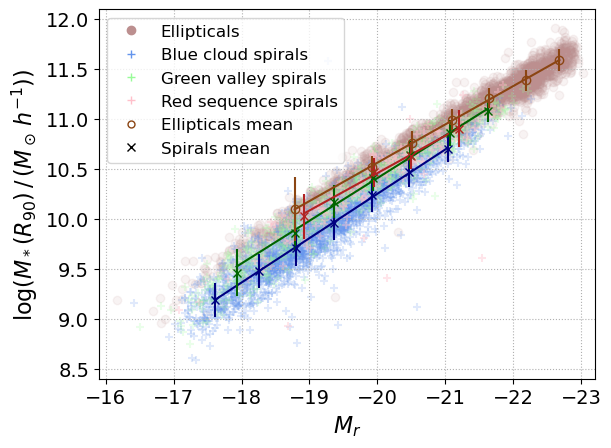

In [368]:
plt.scatter(ellipticals['rabsmag'], ellipticals['e_M_star_R90_h'], color='rosybrown', marker='o', alpha=0.1)
plt.scatter(blue_HI_spirals['rabsmag'], blue_HI_spirals['M90_disk_h'], color='cornflowerblue', marker='+', alpha=0.2)
plt.scatter(green_HI_spirals['rabsmag'], green_HI_spirals['M90_disk_h'], color='palegreen', marker='+', alpha=0.2)
plt.scatter(red_HI_spirals['rabsmag'], red_HI_spirals['M90_disk_h'], color='pink', marker='+', alpha=0.4)

# blue spirals
plt.errorbar(fig10_data['BLUE_SPIRALS_MSTAR'].data['X'],
              fig10_data['BLUE_SPIRALS_MSTAR'].data['Y'],
              yerr=fig10_data['BLUE_SPIRALS_MSTAR'].data['YERR'],
             marker='x',
             color='navy',
            linestyle='none'
            )

plt.plot(fig10_data['BLUE_SPIRALS_MSTAR'].data['X'], 
         fig10_data['BLUE_SPIRALS_MSTAR'].data['X']*fig10_data['BLUE_SPIRALS_MSTAR_FIT'].data['SLOPE'] + fig10_data['BLUE_SPIRALS_MSTAR_FIT'].data['YINT'],
         color='navy'
        )
# green spirals
plt.errorbar(fig10_data['GREEN_SPIRALS_MSTAR'].data['X'],
              fig10_data['GREEN_SPIRALS_MSTAR'].data['Y'],
              yerr=fig10_data['GREEN_SPIRALS_MSTAR'].data['YERR'],
             marker='x',
             color='darkgreen',
             linestyle='none'
            )
plt.plot(fig10_data['GREEN_SPIRALS_MSTAR'].data['X'], 
         fig10_data['GREEN_SPIRALS_MSTAR'].data['X']*fig10_data['GREEN_SPIRALS_MSTAR_FIT'].data['SLOPE'] + fig10_data['GREEN_SPIRALS_MSTAR_FIT'].data['YINT'],
         color='darkgreen'
        )

# red spirals

plt.errorbar(fig10_data['RED_SPIRALS_MSTAR'].data['X'],
              fig10_data['RED_SPIRALS_MSTAR'].data['Y'],
              yerr=fig10_data['RED_SPIRALS_MSTAR'].data['YERR'],
             marker='x',
             color='firebrick',
             linestyle='none'
            )
plt.plot(fig10_data['RED_SPIRALS_MSTAR'].data['X'], 
         fig10_data['RED_SPIRALS_MSTAR'].data['X']*fig10_data['RED_SPIRALS_MSTAR_FIT'].data['SLOPE'] + fig10_data['RED_SPIRALS_MSTAR_FIT'].data['YINT'],
         color='firebrick'
        )


# ELLIPTICALS


plt.errorbar(fig10_data['ELLIPTICALS_MSTAR'].data['X'],
              fig10_data['ELLIPTICALS_MSTAR'].data['Y'],
              yerr=fig10_data['ELLIPTICALS_MSTAR'].data['YERR'],
             marker='o',
             mfc='none',
             color='saddlebrown',
             linestyle='none'
            )

plt.plot(fig10_data['ELLIPTICALS_MSTAR'].data['X'], 
         fig10_data['ELLIPTICALS_MSTAR'].data['X']*fig10_data['ELLIPTICALS_MSTAR_FIT'].data['SLOPE'] + fig10_data['ELLIPTICALS_MSTAR_FIT'].data['YINT'],
         color='saddlebrown'
        )


legend_elements = [Line2D([0], [0], marker='o', color='w', label='Ellipticals',
                          markeredgecolor='rosybrown', markerfacecolor='rosybrown', markersize=6),
                   Line2D([0], [0], marker='+', color='w', label='Blue cloud spirals',
                          markeredgecolor='cornflowerblue', markerfacecolor='cornflowerblue', markersize=6),
                   Line2D([0], [0], marker='+', color='w', label='Green valley spirals',
                          markeredgecolor='palegreen', markerfacecolor='palegreen', markersize=6),
                   Line2D([0], [0], marker='+', color='w', label='Red sequence spirals',
                          markeredgecolor='pink', markerfacecolor='pink', markersize=6),
                   
                  Line2D([0], [0], marker='o', color='w', label='Ellipticals mean',
                          markeredgecolor='saddlebrown', markerfacecolor='none', markersize=5),
                  Line2D([0], [0], marker='x', color='w', label='Spirals mean',
                          markeredgecolor='k', markerfacecolor='none', markersize=6)]

plt.legend(handles=legend_elements, fontsize=12, loc='upper left')

plt.xlim(-15.9,-23.2)
plt.ylim(8.4,12.1)
plt.tick_params(labelsize=14)
plt.grid( linestyle=':')

plt.xlabel(r'$M_r$', fontsize=16)
plt.ylabel(r'$\log(M_*(R_{90})\,/\,(M_\odot\, h^{-1}))$', fontsize=16)
plt.savefig(plot_dir + 'Mstar_Mr_Ravi26.png', bbox_inches='tight')

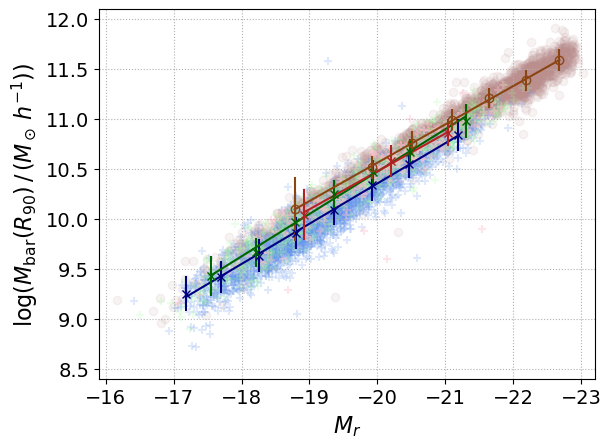

In [369]:
plt.scatter(ellipticals['rabsmag'], ellipticals['e_M_star_R90_h'], color='rosybrown', marker='o', alpha=0.1)
plt.scatter(HI_spirals['rabsmag'][HI_spirals['CMD_class']==1], HI_spirals_mbar[HI_spirals['CMD_class']==1], color='cornflowerblue', marker='+', alpha=0.2)
plt.scatter(HI_spirals['rabsmag'][HI_spirals['CMD_class']==2], HI_spirals_mbar[HI_spirals['CMD_class']==2], color='palegreen', marker='+', alpha=0.2)
plt.scatter(HI_spirals['rabsmag'][HI_spirals['CMD_class']==3], HI_spirals_mbar[HI_spirals['CMD_class']==3], color='pink', marker='+', alpha=0.4)


# blue spirals
plt.errorbar(fig10_data['BLUE_SPIRALS_MBAR'].data['X'],
              fig10_data['BLUE_SPIRALS_MBAR'].data['Y'],
              yerr=fig10_data['BLUE_SPIRALS_MBAR'].data['YERR'],
             marker='x',
             color='navy',
            linestyle='none'
            )

plt.plot(fig10_data['BLUE_SPIRALS_MBAR'].data['X'], 
         fig10_data['BLUE_SPIRALS_MBAR'].data['X']*fig10_data['BLUE_SPIRALS_MBAR_FIT'].data['SLOPE'] + fig10_data['BLUE_SPIRALS_MBAR_FIT'].data['YINT'],
         color='navy'
        )
# green spirals
plt.errorbar(fig10_data['GREEN_SPIRALS_MBAR'].data['X'],
              fig10_data['GREEN_SPIRALS_MBAR'].data['Y'],
              yerr=fig10_data['GREEN_SPIRALS_MBAR'].data['YERR'],
             marker='x',
             color='darkgreen',
             linestyle='none'
            )
plt.plot(fig10_data['GREEN_SPIRALS_MBAR'].data['X'], 
         fig10_data['GREEN_SPIRALS_MBAR'].data['X']*fig10_data['GREEN_SPIRALS_MBAR_FIT'].data['SLOPE'] + fig10_data['GREEN_SPIRALS_MBAR_FIT'].data['YINT'],
         color='darkgreen'
        )

# red spirals

plt.errorbar(fig10_data['RED_SPIRALS_MBAR'].data['X'],
              fig10_data['RED_SPIRALS_MBAR'].data['Y'],
              yerr=fig10_data['RED_SPIRALS_MBAR'].data['YERR'],
             marker='x',
             color='firebrick',
             linestyle='none'
            )
plt.plot(fig10_data['RED_SPIRALS_MBAR'].data['X'], 
         fig10_data['RED_SPIRALS_MBAR'].data['X']*fig10_data['RED_SPIRALS_MBAR_FIT'].data['SLOPE'] + fig10_data['RED_SPIRALS_MBAR_FIT'].data['YINT'],
         color='firebrick'
        )


# ELLIPTICALS


plt.errorbar(fig10_data['ELLIPTICALS_MSTAR'].data['X'],
              fig10_data['ELLIPTICALS_MSTAR'].data['Y'],
              yerr=fig10_data['ELLIPTICALS_MSTAR'].data['YERR'],
             marker='o',
             mfc='none',
             color='saddlebrown',
             linestyle='none'
            )

plt.plot(fig10_data['ELLIPTICALS_MSTAR'].data['X'], 
         fig10_data['ELLIPTICALS_MSTAR'].data['X']*fig10_data['ELLIPTICALS_MSTAR_FIT'].data['SLOPE'] + fig10_data['ELLIPTICALS_MSTAR_FIT'].data['YINT'],
         color='saddlebrown'
        )


legend_elements = [Line2D([0], [0], marker='o', color='w', label='Ellipticals',
                          markeredgecolor='rosybrown', markerfacecolor='rosybrown', markersize=6),
                   Line2D([0], [0], marker='+', color='w', label='Blue cloud spirals',
                          markeredgecolor='cornflowerblue', markerfacecolor='cornflowerblue', markersize=6),
                   Line2D([0], [0], marker='+', color='w', label='Green valley spirals',
                          markeredgecolor='palegreen', markerfacecolor='palegreen', markersize=6),
                   Line2D([0], [0], marker='+', color='w', label='Red sequence spirals',
                          markeredgecolor='pink', markerfacecolor='pink', markersize=6),
                   
                  Line2D([0], [0], marker='o', color='w', label='Ellipticals mean',
                          markeredgecolor='maroon', markerfacecolor='none', markersize=5),
                  Line2D([0], [0], marker='x', color='w', label='Spirals mean',
                          markeredgecolor='k', markerfacecolor='none', markersize=6)]

# plt.legend(handles=legend_elements)
plt.xlim(-15.9,-23.2)
plt.ylim(8.4,12.1)
plt.tick_params(labelsize=14)
plt.grid( linestyle=':')

plt.xlabel(r'$M_r$', fontsize=16)
plt.ylabel(r'$\log(M_{\rm bar}(R_{90})\,/\,(M_\odot\, h^{-1}))$', fontsize=16)
plt.savefig(plot_dir + 'Mbar_Mr_Ravi26.png', bbox_inches='tight')

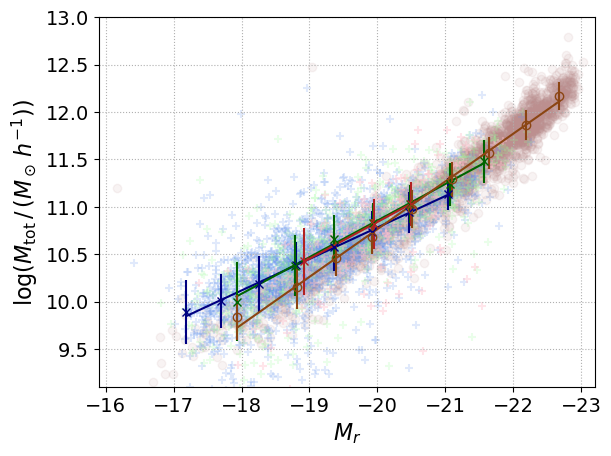

In [370]:
plt.scatter(ellipticals['rabsmag'], ellipticals['Mvir'], color='rosybrown', marker='o', alpha=0.1)
plt.scatter(blue_HI_spirals['rabsmag'], blue_HI_spirals['M_R90'], color='cornflowerblue', marker='+', alpha=0.2)
plt.scatter(green_HI_spirals['rabsmag'], green_HI_spirals['M_R90'], color='palegreen', marker='+', alpha=0.2)
plt.scatter(red_HI_spirals['rabsmag'], red_HI_spirals['M_R90'], color='pink', marker='+', alpha=0.4)

# blue spirals
plt.errorbar(fig10_data['BLUE_SPIRALS_MTOT'].data['X'],
              fig10_data['BLUE_SPIRALS_MTOT'].data['Y'],
              yerr=fig10_data['BLUE_SPIRALS_MTOT'].data['YERR'],
             marker='x',
             color='navy',
            linestyle='none'
            )

plt.plot(fig10_data['BLUE_SPIRALS_MTOT'].data['X'], 
         fig10_data['BLUE_SPIRALS_MTOT'].data['X']*fig10_data['BLUE_SPIRALS_MTOT_FIT'].data['SLOPE'] + fig10_data['BLUE_SPIRALS_MTOT_FIT'].data['YINT'],
         color='navy'
        )
# green spirals
plt.errorbar(fig10_data['GREEN_SPIRALS_MTOT'].data['X'],
              fig10_data['GREEN_SPIRALS_MTOT'].data['Y'],
              yerr=fig10_data['GREEN_SPIRALS_MTOT'].data['YERR'],
             marker='x',
             color='darkgreen',
             linestyle='none'
            )
plt.plot(fig10_data['GREEN_SPIRALS_MTOT'].data['X'], 
         fig10_data['GREEN_SPIRALS_MTOT'].data['X']*fig10_data['GREEN_SPIRALS_MTOT_FIT'].data['SLOPE'] + fig10_data['GREEN_SPIRALS_MTOT_FIT'].data['YINT'],
         color='darkgreen'
        )

# red spirals

plt.errorbar(fig10_data['RED_SPIRALS_MTOT'].data['X'],
              fig10_data['RED_SPIRALS_MTOT'].data['Y'],
              yerr=fig10_data['RED_SPIRALS_MTOT'].data['YERR'],
             marker='x',
             color='firebrick',
             linestyle='none'
            )
plt.plot(fig10_data['RED_SPIRALS_MTOT'].data['X'], 
         fig10_data['RED_SPIRALS_MTOT'].data['X']*fig10_data['RED_SPIRALS_MTOT_FIT'].data['SLOPE'] + fig10_data['RED_SPIRALS_MTOT_FIT'].data['YINT'],
         color='firebrick'
        )


# ELLIPTICALS


plt.errorbar(fig10_data['ELLIPTICALS_MTOT'].data['X'],
              fig10_data['ELLIPTICALS_MTOT'].data['Y'],
              yerr=fig10_data['ELLIPTICALS_MTOT'].data['YERR'],
             marker='o',
             mfc='none',
             color='saddlebrown',
             linestyle='none'
            )

plt.plot(fig10_data['ELLIPTICALS_MTOT'].data['X'], 
         fig10_data['ELLIPTICALS_MTOT'].data['X']*fig10_data['ELLIPTICALS_MTOT_FIT'].data['SLOPE'] + fig10_data['ELLIPTICALS_MTOT_FIT'].data['YINT'],
         color='saddlebrown'
        )


legend_elements = [Line2D([0], [0], marker='o', color='w', label='Ellipticals',
                          markeredgecolor='rosybrown', markerfacecolor='rosybrown', markersize=6),
                   Line2D([0], [0], marker='+', color='w', label='Blue cloud spirals',
                          markeredgecolor='cornflowerblue', markerfacecolor='cornflowerblue', markersize=6),
                   Line2D([0], [0], marker='+', color='w', label='Green valley spirals',
                          markeredgecolor='palegreen', markerfacecolor='palegreen', markersize=6),
                   Line2D([0], [0], marker='+', color='w', label='Red sequence spirals',
                          markeredgecolor='pink', markerfacecolor='pink', markersize=6),
                   
                  Line2D([0], [0], marker='o', color='w', label='Ellipticals mean',
                          markeredgecolor='maroon', markerfacecolor='none', markersize=5),
                  Line2D([0], [0], marker='x', color='w', label='Spirals mean',
                          markeredgecolor='k', markerfacecolor='none', markersize=6)]

# plt.legend(handles=legend_elements)

plt.xlim(-15.9,-23.2)
plt.ylim(9.1,13)
plt.tick_params(labelsize=14)
plt.grid( linestyle=':')

plt.xlabel(r'$M_r$', fontsize=16)
plt.ylabel(r'$\log(M_{\rm tot}\,/\,(M_\odot\, h^{-1}))$', fontsize=16)
plt.savefig(plot_dir + 'Mtot_Mr_Ravi26.png', bbox_inches='tight')

## central stellar metallicity vs Mr for all galaxy classes

In [371]:
good_stelz = master_table[(master_table['stellar_grad_Z'] != 1) & (~master_table['stellar_grad_Z'].mask)]

In [372]:
spirals = good_stelz[good_stelz['spiral_mask']==1]
ellipticals = good_stelz[good_stelz['elliptical_mask']==1]
not_sample = good_stelz[(good_stelz['spiral_mask']==0) & (good_stelz['elliptical_mask']==0)]

In [373]:
b_spirals = spirals[spirals['CMD_class']==1]
g_spirals = spirals[spirals['CMD_class']==2]
r_spirals = spirals[spirals['CMD_class']==3]

In [374]:
mr_bins = np.linspace(np.min([np.min(spirals['rabsmag']), np.min(ellipticals['rabsmag'])])-0.01,
                  np.max([np.max(spirals['rabsmag']), np.max(ellipticals['rabsmag'])]), 15)

In [375]:
mr_bins

array([-23.1145    , -22.54364286, -21.97278571, -21.40192857,
       -20.83107143, -20.26021429, -19.68935714, -19.1185    ,
       -18.54764286, -17.97678571, -17.40592857, -16.83507143,
       -16.26421429, -15.69335714, -15.1225    ])

### ellipticals 

In [376]:
e_ctrs = []
e_stelz = []
e_mr_bins = np.concatenate([mr_bins[:9], mr_bins[-1:]])
indices = np.digitize(ellipticals['rabsmag'], e_mr_bins, right=True)
e_edges = []

for i in range(1,len(e_mr_bins)):

    e_stelz.append(ellipticals['stellar_Z_0'][indices==i])
    e_ctrs.append(np.mean(ellipticals['rabsmag'][indices==i]))
    e_edges.append([np.min(ellipticals['rabsmag'][indices==i]), np.max(ellipticals['rabsmag'][indices==i])])

e_stelz_avg, e_stelz_sig = fit_to_gaussian(e_stelz, plot_dir = plot_dir + 'stelz_mr/ellipticals/', plot_name='ellipticals_stelz_Mr', xlab=r'$M_*$', plot_bins=mr_bins, bin_lab=r'$M_r$', bin_order='flip')
# e_stelz_popt, e_stelz_pcov = curve_fit(lin_fit, e_ctrs, 
#                                        e_mstar_avg, sigma=e_mstar_sig)
# print(e_stelz_popt, np.sqrt(e_stelz_pcov[0,0]), np.sqrt(e_stelz_pcov[1,1]))


0
1


/Users/nityaravi/miniforge3/envs/RotationCurves/lib/python3.12/site-packages/numpy/core/fromnumeric.py:771: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedColumn.
  a.partition(kth, axis=axis, kind=kind, order=order)


2
3
4
5
6
7
8


### blue spirals

In [377]:
bs_ctrs = []
bs_stelz = []
bs_mr_bins = mr_bins
bs_mr_bins = np.concatenate([mr_bins[:1], mr_bins[2:-5], mr_bins[-1:]])
indices = np.digitize(b_spirals['rabsmag'], bs_mr_bins, right=True)
bs_edges = []

for i in range(1,len(bs_mr_bins)):

    bs_stelz.append(b_spirals['stellar_Z_0'][indices==i])
    bs_ctrs.append(np.mean(b_spirals['rabsmag'][indices==i]))
    bs_edges.append([np.min(b_spirals['rabsmag'][indices==i]), np.max(b_spirals['rabsmag'][indices==i])])


bs_stelz_avg, bs_stelz_sig = fit_to_gaussian(bs_stelz, plot_dir = plot_dir + 'stelz_mr/bspirals/', plot_name='bspirals_stelz_Mr', xlab=r'$M_*$', plot_bins=bs_mr_bins, bin_lab=r'$M_r$', bin_order='flip')
# e_stelz_popt, e_stelz_pcov = curve_fit(lin_fit, e_ctrs, 
#                                        e_mstar_avg, sigma=e_mstar_sig)
# print(e_stelz_popt, np.sqrt(e_stelz_pcov[0,0]), np.sqrt(e_stelz_pcov[1,1]))


0
1
2
3
4
5
6
7
8


### green spirals

In [378]:
gs_ctrs = []
gs_stelz = []
# gs_mr_bins = mr_bins
gs_mr_bins = np.concatenate([mr_bins[:1], mr_bins[2:-5], mr_bins[-1:]])
indices = np.digitize(g_spirals['rabsmag'], gs_mr_bins, right=True)
gs_edges = []

for i in range(1,len(gs_mr_bins)):

    gs_stelz.append(g_spirals['stellar_Z_0'][indices==i])
    gs_ctrs.append(np.mean(g_spirals['rabsmag'][indices==i]))
    gs_edges.append([np.min(g_spirals['rabsmag'][indices==i]), np.max(g_spirals['rabsmag'][indices==i])])


gs_stelz_avg, gs_stelz_sig = fit_to_gaussian(gs_stelz, plot_dir = plot_dir + 'stelz_mr/gspirals/', plot_name='gspirals_stelz_Mr', xlab=r'$M_*$', plot_bins=gs_mr_bins, bin_lab=r'$M_r$', bin_order='flip')
# e_stelz_popt, e_stelz_pcov = curve_fit(lin_fit, e_ctrs, 
#                                        e_mstar_avg, sigma=e_mstar_sig)
# print(e_stelz_popt, np.sqrt(e_stelz_pcov[0,0]), np.sqrt(e_stelz_pcov[1,1]))


0
1
2
3
4
5
6
7
8


### red spirals

In [379]:
rs_ctrs = []
rs_stelz = []
rs_mr_bins = mr_bins
rs_mr_bins = np.concatenate([mr_bins[:1], mr_bins[3:-7], mr_bins[-1:]])
indices = np.digitize(r_spirals['rabsmag'], rs_mr_bins, right=True)
rs_edges = []

for i in range(1,len(rs_mr_bins)):

    rs_stelz.append(r_spirals['stellar_Z_0'][indices==i])
    rs_ctrs.append(np.mean(r_spirals['rabsmag'][indices==i]))
    rs_edges.append([np.min(r_spirals['rabsmag'][indices==i]), np.max(r_spirals['rabsmag'][indices==i])])


rs_stelz_avg, rs_stelz_sig = fit_to_gaussian(rs_stelz, plot_dir = plot_dir + 'stelz_mr/rspirals/', plot_name='rspirals_stelz_Mr', xlab=r'$M_*$', plot_bins=rs_mr_bins, bin_lab=r'$M_r$', bin_order='flip')
# e_stelz_popt, e_stelz_pcov = curve_fit(lin_fit, e_ctrs, 
#                                        e_mstar_avg, sigma=e_mstar_sig)
# print(e_stelz_popt, np.sqrt(e_stelz_pcov[0,0]), np.sqrt(e_stelz_pcov[1,1]))


0
1
2
3
4
5


In [380]:
o_ctrs = []
o_stelz = []
o_mr_bins = mr_bins
o_mr_bins = np.concatenate([mr_bins[:0], mr_bins[2:-4], mr_bins[-1:]])
indices = np.digitize(not_sample['rabsmag'], o_mr_bins, right=True)
o_edges = []

for i in range(1,len(o_mr_bins)):

    o_stelz.append(not_sample['stellar_Z_0'][indices==i])
    o_ctrs.append(np.mean(not_sample['rabsmag'][indices==i]))
    o_edges.append([np.min(not_sample['rabsmag'][indices==i]), np.max(not_sample['rabsmag'][indices==i])])

o_stelz_avg, o_stelz_sig = fit_to_gaussian(o_stelz, plot_dir = plot_dir + 'stelz_mr/other/', plot_name='other_stelz_Mr', xlab=r'$M_*$', plot_bins=o_mr_bins, bin_lab=r'$M_r$', bin_order='flip')
# e_stelz_popt, e_stelz_pcov = curve_fit(lin_fit, e_ctrs, 
#                                        e_mstar_avg, sigma=e_mstar_sig)
# print(e_stelz_popt, np.sqrt(e_stelz_pcov[0,0]), np.sqrt(e_stelz_pcov[1,1]))


0
1
2
3
4
5
6
7
8


### plot

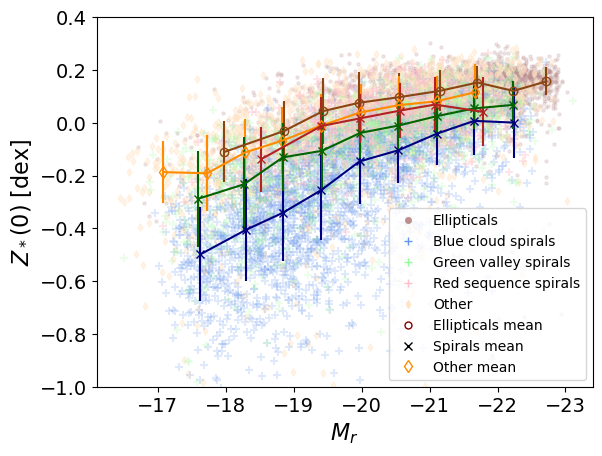

In [381]:

plt.scatter(ellipticals['rabsmag'], ellipticals['stellar_Z_0'], 
            marker='o', alpha=0.2, color='rosybrown', s=5)
plt.scatter(not_sample['rabsmag'], not_sample['stellar_Z_0'], 
            marker='d', alpha=0.4, color='bisque', s=15)
plt.scatter(b_spirals['rabsmag'], b_spirals['stellar_Z_0'], 
            marker='+', alpha=0.2, color='cornflowerblue')
plt.scatter(g_spirals['rabsmag'], g_spirals['stellar_Z_0'], 
            marker='+', alpha=0.2, color='palegreen')
plt.scatter(r_spirals['rabsmag'], r_spirals['stellar_Z_0'], 
            marker='+', alpha=0.4, color='pink', )


plt.errorbar(e_ctrs, e_stelz_avg, yerr=e_stelz_sig, #xerr=np.abs(np.array(e_edges).transpose() - e_ctrs),
             color='saddlebrown', marker='o', markerfacecolor='none',)
plt.errorbar(o_ctrs, o_stelz_avg, yerr=o_stelz_sig, #xerr=np.abs(np.array(o_edges).transpose() - o_ctrs),
             color='darkorange', marker='d', markerfacecolor='none')
plt.errorbar(bs_ctrs, bs_stelz_avg, yerr=bs_stelz_sig, #xerr=np.abs(np.array(bs_edges).transpose() - bs_ctrs),
             color='navy', marker='x')
plt.errorbar(gs_ctrs, gs_stelz_avg, yerr=gs_stelz_sig, #xerr=np.abs(np.array(gs_edges).transpose() - gs_ctrs),
             color='darkgreen', marker='x')
plt.errorbar(rs_ctrs, rs_stelz_avg, yerr=rs_stelz_sig, #xerr=np.abs(np.array(rs_edges).transpose() - rs_ctrs),
             color='firebrick', marker='x')


legend_elements = [Line2D([0], [0], marker='o', color='w', label='Ellipticals',
                          markeredgecolor='rosybrown', markerfacecolor='rosybrown', markersize=4),
                   Line2D([0], [0], marker='+', color='w', label='Blue cloud spirals',
                          markeredgecolor='cornflowerblue', markerfacecolor='cornflowerblue', markersize=6),
                   Line2D([0], [0], marker='+', color='w', label='Green valley spirals',
                          markeredgecolor='palegreen', markerfacecolor='palegreen', markersize=6),
                   Line2D([0], [0], marker='+', color='w', label='Red sequence spirals',
                          markeredgecolor='pink', markerfacecolor='pink', markersize=6),
                   Line2D([0], [0], marker='d', color='w', label='Other',
                          markeredgecolor='bisque', markerfacecolor='bisque', markersize=4),
                   
                  Line2D([0], [0], marker='o', color='w', label='Ellipticals mean',
                          markeredgecolor='maroon', markerfacecolor='none', markersize=5),
                  Line2D([0], [0], marker='x', color='w', label='Spirals mean',
                          markeredgecolor='k', markerfacecolor='none', markersize=6),
                  Line2D([0], [0], marker='d', color='w', label='Other mean',
                          markeredgecolor='darkorange', markerfacecolor='none', markersize=6)]

plt.legend(handles=legend_elements)

plt.xlim(-16.1, -23.4)
plt.ylim(-1,0.4)
plt.tick_params(labelsize=14)
plt.xlabel(r'$M_r$', fontsize=16)
plt.ylabel(r'$Z_*(0)$ [dex]', fontsize=16)

plt.savefig(plot_dir + '/stelz_mr/stelz_mr.png', bbox_inches= 'tight')

In [383]:
e_width = np.array([e_ctrs-e_mr_bins[:-1], e_mr_bins[1:]-e_ctrs])

o_width = np.array([o_ctrs-o_mr_bins[:-1], o_mr_bins[1:]-o_ctrs])
bs_width = np.array([bs_ctrs-bs_mr_bins[:-1], bs_mr_bins[1:]-bs_ctrs])
gs_width = np.array([gs_ctrs-gs_mr_bins[:-1], gs_mr_bins[1:]-gs_ctrs])
rs_width = np.array([rs_ctrs-rs_mr_bins[:-1], rs_mr_bins[1:]-rs_ctrs])

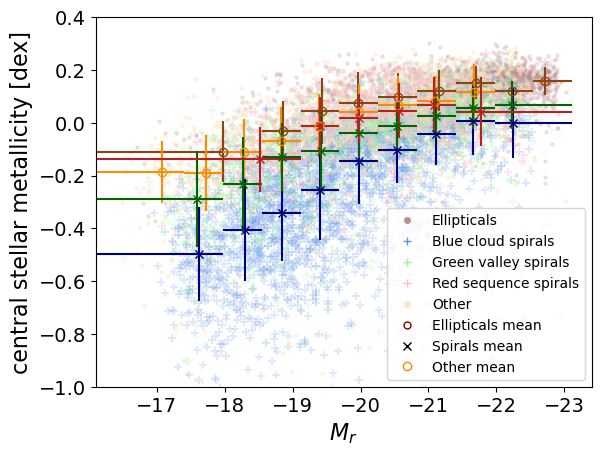

In [384]:

plt.scatter(ellipticals['rabsmag'], ellipticals['stellar_Z_0'], 
            marker='o', alpha=0.2, color='rosybrown', s=5)
plt.scatter(not_sample['rabsmag'], not_sample['stellar_Z_0'], 
            marker='o', alpha=0.4, color='bisque', s=5)
plt.scatter(b_spirals['rabsmag'], b_spirals['stellar_Z_0'], 
            marker='+', alpha=0.2, color='cornflowerblue')
plt.scatter(g_spirals['rabsmag'], g_spirals['stellar_Z_0'], 
            marker='+', alpha=0.2, color='palegreen')
plt.scatter(r_spirals['rabsmag'], r_spirals['stellar_Z_0'], 
            marker='+', alpha=0.4, color='pink', )


plt.errorbar(e_ctrs, e_stelz_avg, yerr=e_stelz_sig, xerr=e_width,
             color='saddlebrown', marker='o', markerfacecolor='none', linestyle='none')
plt.errorbar(o_ctrs, o_stelz_avg, yerr=o_stelz_sig, xerr=o_width,
             color='darkorange', marker='o', markerfacecolor='none', linestyle='none')
plt.errorbar(bs_ctrs, bs_stelz_avg, yerr=bs_stelz_sig, xerr=bs_width,
             color='navy', marker='x', linestyle='none')
plt.errorbar(gs_ctrs, gs_stelz_avg, yerr=gs_stelz_sig, xerr=gs_width,
             color='darkgreen', marker='x', linestyle='none')
plt.errorbar(rs_ctrs, rs_stelz_avg, yerr=rs_stelz_sig, xerr=rs_width,
             color='firebrick', marker='x', linestyle='none')


legend_elements = [Line2D([0], [0], marker='o', color='w', label='Ellipticals',
                          markeredgecolor='rosybrown', markerfacecolor='rosybrown', markersize=4),
                   Line2D([0], [0], marker='+', color='w', label='Blue cloud spirals',
                          markeredgecolor='cornflowerblue', markerfacecolor='cornflowerblue', markersize=6),
                   Line2D([0], [0], marker='+', color='w', label='Green valley spirals',
                          markeredgecolor='palegreen', markerfacecolor='palegreen', markersize=6),
                   Line2D([0], [0], marker='+', color='w', label='Red sequence spirals',
                          markeredgecolor='pink', markerfacecolor='pink', markersize=6),
                   Line2D([0], [0], marker='o', color='w', label='Other',
                          markeredgecolor='bisque', markerfacecolor='bisque', markersize=4),
                   
                  Line2D([0], [0], marker='o', color='w', label='Ellipticals mean',
                          markeredgecolor='maroon', markerfacecolor='none', markersize=5),
                  Line2D([0], [0], marker='x', color='w', label='Spirals mean',
                          markeredgecolor='k', markerfacecolor='none', markersize=6),
                  Line2D([0], [0], marker='o', color='w', label='Other mean',
                          markeredgecolor='darkorange', markerfacecolor='none', markersize=6)]

plt.legend(handles=legend_elements)

plt.xlim(-16.1, -23.4)
plt.ylim(-1,0.4)
plt.tick_params(labelsize=14)
plt.xlabel(r'$M_r$', fontsize=16)
plt.ylabel(r'central stellar metallicity [dex]', fontsize=16)

plt.savefig(plot_dir + '/stelz_mr/stelz_mr_v2.png', bbox_inches= 'tight')

## metallicity at R50

In [385]:
e_ctrs = []
e_stelz = []
e_mr_bins = np.concatenate([mr_bins[:9], mr_bins[-1:]])
indices = np.digitize(ellipticals['rabsmag'], e_mr_bins, right=True)

for i in range(1,len(e_mr_bins)):

    e_stelz.append(ellipticals['stellar_Z_Re'][indices==i])
    e_ctrs.append(np.mean(ellipticals['rabsmag'][indices==i]))

e_stelz_avg, e_stelz_sig = fit_to_gaussian(e_stelz, plot_dir = plot_dir + 'stelz_Re_mr/ellipticals/', plot_name='ellipticals_stelz_Mr', xlab=r'$M_*$', plot_bins=mr_bins, bin_lab=r'$M_r$', bin_order='flip')
# e_stelz_popt, e_stelz_pcov = curve_fit(lin_fit, e_ctrs, 
#                                        e_mstar_avg, sigma=e_mstar_sig)
# print(e_stelz_popt, np.sqrt(e_stelz_pcov[0,0]), np.sqrt(e_stelz_pcov[1,1]))


0
1
2
3
4
5
6
7
8


In [386]:
bs_ctrs = []
bs_stelz = []
bs_mr_bins = mr_bins
bs_mr_bins = np.concatenate([mr_bins[:0], mr_bins[2:-5], mr_bins[-1:]])
indices = np.digitize(b_spirals['rabsmag'], bs_mr_bins, right=True)

for i in range(1,len(bs_mr_bins)):

    bs_stelz.append(b_spirals['stellar_Z_Re'][indices==i])
    bs_ctrs.append(np.mean(b_spirals['rabsmag'][indices==i]))

bs_stelz_avg, bs_stelz_sig = fit_to_gaussian(bs_stelz, plot_dir = plot_dir + 'stelz_Re_mr/bspirals/', plot_name='bspirals_stelz_Mr', xlab=r'$M_*$', plot_bins=bs_mr_bins, bin_lab=r'$M_r$', bin_order='flip')
# e_stelz_popt, e_stelz_pcov = curve_fit(lin_fit, e_ctrs, 
#                                        e_mstar_avg, sigma=e_mstar_sig)
# print(e_stelz_popt, np.sqrt(e_stelz_pcov[0,0]), np.sqrt(e_stelz_pcov[1,1]))


0
1
2
3
4
5
6
7


In [387]:
gs_ctrs = []
gs_stelz = []
# gs_mr_bins = mr_bins
gs_mr_bins = np.concatenate([mr_bins[:0], mr_bins[2:-5], mr_bins[-1:]])
indices = np.digitize(g_spirals['rabsmag'], gs_mr_bins, right=True)

for i in range(1,len(gs_mr_bins)):

    gs_stelz.append(g_spirals['stellar_Z_Re'][indices==i])
    gs_ctrs.append(np.mean(g_spirals['rabsmag'][indices==i]))

gs_stelz_avg, gs_stelz_sig = fit_to_gaussian(gs_stelz, plot_dir = plot_dir + 'stelz_Re_mr/gspirals/', plot_name='gspirals_stelz_Mr', xlab=r'$M_*$', plot_bins=gs_mr_bins, bin_lab=r'$M_r$', bin_order='flip')
# e_stelz_popt, e_stelz_pcov = curve_fit(lin_fit, e_ctrs, 
#                                        e_mstar_avg, sigma=e_mstar_sig)
# print(e_stelz_popt, np.sqrt(e_stelz_pcov[0,0]), np.sqrt(e_stelz_pcov[1,1]))


0
1
2
3
4
5
6
7


In [388]:
rs_ctrs = []
rs_stelz = []
rs_mr_bins = mr_bins
rs_mr_bins = np.concatenate([mr_bins[:0], mr_bins[2:-7], mr_bins[-1:]])
indices = np.digitize(r_spirals['rabsmag'], rs_mr_bins, right=True)

for i in range(1,len(rs_mr_bins)):

    rs_stelz.append(r_spirals['stellar_Z_Re'][indices==i])
    rs_ctrs.append(np.mean(r_spirals['rabsmag'][indices==i]))

rs_stelz_avg, rs_stelz_sig = fit_to_gaussian(rs_stelz, plot_dir = plot_dir + 'stelz_Re_mr/rspirals/', plot_name='rspirals_stelz_Mr', xlab=r'$M_*$', plot_bins=rs_mr_bins, bin_lab=r'$M_r$', bin_order='flip')
# e_stelz_popt, e_stelz_pcov = curve_fit(lin_fit, e_ctrs, 
#                                        e_mstar_avg, sigma=e_mstar_sig)
# print(e_stelz_popt, np.sqrt(e_stelz_pcov[0,0]), np.sqrt(e_stelz_pcov[1,1]))


0
1
2
3
4
5


In [389]:
o_ctrs = []
o_stelz = []
o_mr_bins = mr_bins
o_mr_bins = np.concatenate([mr_bins[:0], mr_bins[2:-4], mr_bins[-1:]])
indices = np.digitize(not_sample['rabsmag'], o_mr_bins, right=True)

for i in range(1,len(o_mr_bins)):

    o_stelz.append(not_sample['stellar_Z_Re'][np.logical_and(indices==i, np.abs(not_sample['stellar_Z_Re'])<30 )])
    o_ctrs.append(np.mean(not_sample['rabsmag'][indices==i]))

o_stelz_avg, o_stelz_sig = fit_to_gaussian(o_stelz, plot_dir = plot_dir + 'stelz_Re_mr/other/', plot_name='other_stelz_Mr', xlab=r'$M_*$', plot_bins=o_mr_bins, bin_lab=r'$M_r$', bin_order='flip')
# e_stelz_popt, e_stelz_pcov = curve_fit(lin_fit, e_ctrs, 
#                                        e_mstar_avg, sigma=e_mstar_sig)
# print(e_stelz_popt, np.sqrt(e_stelz_pcov[0,0]), np.sqrt(e_stelz_pcov[1,1]))


0
1
2
3
4
5
6
7
8


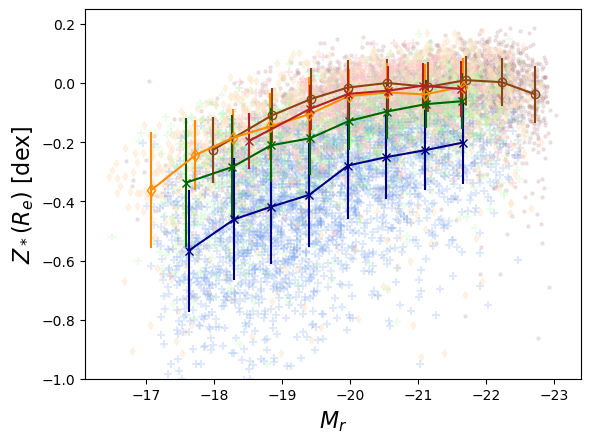

In [390]:
plt.scatter(ellipticals['rabsmag'], ellipticals['stellar_Z_Re'], 
            marker='o', alpha=0.2, color='rosybrown', s=5)
plt.scatter(not_sample['rabsmag'], not_sample['stellar_Z_Re'], 
            marker='d', alpha=0.4, color='bisque', s=15)
plt.scatter(b_spirals['rabsmag'], b_spirals['stellar_Z_Re'], 
            marker='+', alpha=0.2, color='cornflowerblue')
plt.scatter(g_spirals['rabsmag'], g_spirals['stellar_Z_Re'], 
            marker='+', alpha=0.2, color='palegreen')
plt.scatter(r_spirals['rabsmag'], r_spirals['stellar_Z_Re'], 
            marker='+', alpha=0.4, color='pink', )

plt.errorbar(e_ctrs, e_stelz_avg, yerr=e_stelz_sig, color='saddlebrown', marker='o', markerfacecolor='none')
plt.errorbar(o_ctrs, o_stelz_avg, yerr=o_stelz_sig, color='darkorange', marker='d', markerfacecolor='none')
plt.errorbar(bs_ctrs, bs_stelz_avg, yerr=bs_stelz_sig, color='navy', marker='x')
plt.errorbar(gs_ctrs, gs_stelz_avg, yerr=gs_stelz_sig, color='darkgreen', marker='x')
plt.errorbar(rs_ctrs, rs_stelz_avg, yerr=rs_stelz_sig, color='firebrick', marker='x')


plt.ylim(-1,0.25)
plt.xlim(-16.1, -23.4)
plt.xlabel(r'$M_r$', fontsize=16)
plt.ylabel(r'$Z_*(R_e)$ [dex]', fontsize=16)

plt.savefig(plot_dir + '/stelz_Re_mr/stelz_Re_mr.png', bbox_inches= 'tight')

Text(0, 0.5, '$12 + \\log(O/H)$ at $R_e$ [dex]')

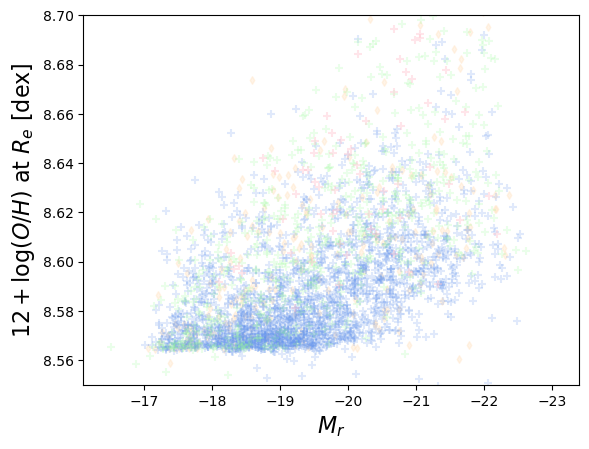

In [391]:
plt.scatter(ellipticals['rabsmag'], ellipticals['gas_Z_Re'], 
            marker='o', alpha=0.2, color='rosybrown', s=5)
plt.scatter(not_sample['rabsmag'], not_sample['gas_Z_Re'], 
            marker='d', alpha=0.4, color='bisque', s=15)
plt.scatter(b_spirals['rabsmag'], b_spirals['gas_Z_Re'], 
            marker='+', alpha=0.2, color='cornflowerblue')
plt.scatter(g_spirals['rabsmag'], g_spirals['gas_Z_Re'], 
            marker='+', alpha=0.2, color='palegreen')
plt.scatter(r_spirals['rabsmag'], r_spirals['gas_Z_Re'], 
            marker='+', alpha=0.4, color='pink', )


plt.ylim(8.55,8.7)
plt.xlim(-16.1, -23.4)
plt.xlabel(r'$M_r$', fontsize=16)
plt.ylabel(r'$12 + \log(O/H)$ at $R_e$ [dex]', fontsize=16)



## central stellar vs gas-phase metallicity

In [392]:
gasz = good_stelz[~good_stelz['Z_0'].mask]

In [393]:
# bins = np.linspace(-0.015, 0.010, 20)
bins = np.quantile(gasz['Z_0'], np.linspace(0,1,20))
indices = np.digitize(gasz['Z_0'], bins)

bin_edges = []
stel_z = []
ctrs = []

for i in range(1,len(bins)):

    stel_z.append(gasz['stellar_Z_0'][indices==i])
    ctrs.append(ma.mean(gasz['Z_0'][indices==i]))
    bin_edges.append([np.min(gasz['Z_0'][indices==i]), np.max(gasz['Z_0'][indices==i])])

stelz_avg, stelz_sig = fit_to_gaussian(stel_z, plot_dir = plot_dir + 'stelz_gasz/', plot_name='stelz_gasz', xlab=r'$stellar Z$', plot_bins=bins, bin_lab=r'$Z$')


/Users/nityaravi/miniforge3/envs/RotationCurves/lib/python3.12/site-packages/numpy/lib/function_base.py:4824: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedColumn.
  arr.partition(


0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18


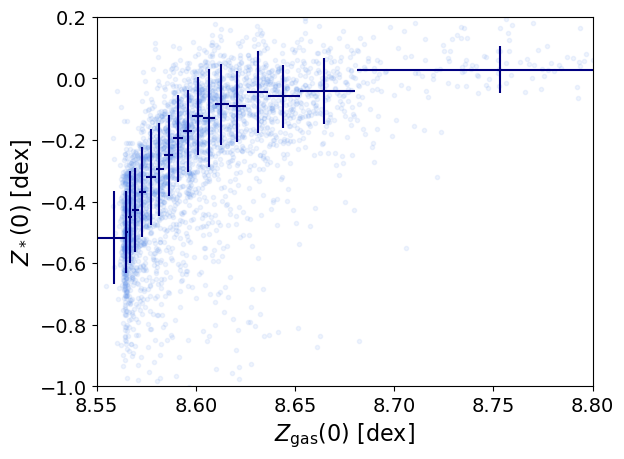

In [394]:
plt.scatter(good_stelz['Z_0'], good_stelz['stellar_Z_0'], marker='.', alpha=0.1, color='cornflowerblue')
plt.errorbar(ctrs, stelz_avg, yerr=stelz_sig, xerr=np.abs(np.array(bin_edges).transpose() - ctrs), linestyle='none', color='navy')
plt.xlim(8.55, 8.8)
plt.ylim(-1,0.2)

plt.ylabel(r'$Z_*(0)$ [dex]', fontsize=16)
plt.xlabel(r'$Z_{\rm gas}(0)$ [dex]', fontsize=16)
plt.tick_params(labelsize=14)


plt.savefig(plot_dir + '/stelz_gasz/stelz_gasz.png', bbox_inches= 'tight')

## compare pip3d to our fit

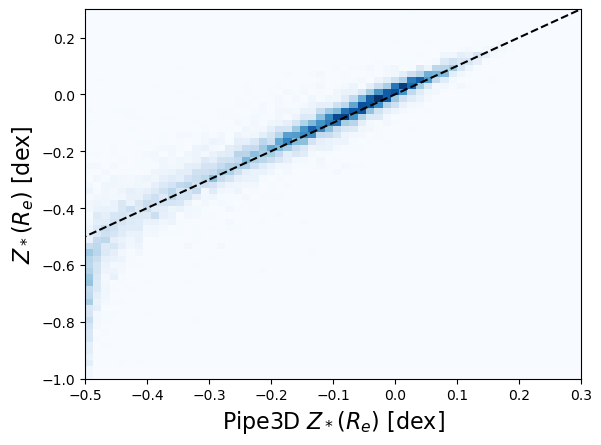

In [395]:
# plt.scatter(good_stelz['stellar_grad_Z'], p3d_slopes_corr, alpha=0.1, marker='.')

plt.hist2d(good_stelz['ZH_LW_Re_fit'], good_stelz['R50_Z'],
           range=[[-0.5,0.3],[-1,0.3]], bins=60, cmap='Blues')
plt.xlim(-0.5,0.3)
plt.ylim(-1,0.3)

plt.xlabel(r'Pipe3D $Z_*(R_e)$ [dex]', fontsize=16)
plt.ylabel('$Z_*(R_e)$ [dex]', fontsize=16)
plt.plot([-1,1],[-1,1], color='k', linestyle='--')

# plt.colorbar(label=r'Numb')

plt.savefig(plot_dir + '/pipe3dZRe.png', format='png', bbox_inches='tight')

## grid plots

In [396]:
alpha_mask = spirals['alpha'] <= 99
vel_mask = np.logical_and(spirals['V_R90'] < 1000, spirals['V_R90'] > 10)
vel_err_mask = spirals['v_max_err']/spirals['v_max'] <= 2

In [397]:
good_spirals = spirals[np.logical_and(np.logical_and(alpha_mask, vel_mask), vel_err_mask)]

In [398]:
good_spirals['mstar_mtot'] = 10**((good_spirals['M90_disk']+np.log10(0.73))-good_spirals['M_R90'])
ellipticals['mstar_mtot'] = 10**(ellipticals['e_M_star_R90_h'] - ellipticals['Mvir'])

In [399]:
mags = np.hstack([good_spirals['rabsmag'], ellipticals['rabsmag']])
mstar_mtot = vstack([good_spirals['mstar_mtot'], ellipticals['mstar_mtot']])
z_star = np.hstack([good_spirals['stellar_Z_0'], ellipticals['stellar_Z_0']])

In [400]:
mr_bins = np.linspace(-17, -23, 6)
z_bins = np.linspace(-1, 0.3, 6)
mr_indices = np.digitize(mags, mr_bins, right=True)
z_indices = np.digitize(z_star, z_bins, right=True)

In [401]:
mstar_mtot_medians = np.zeros((5,5))
for i in range(1,6):
    for j in range(1,6):

        mask = np.logical_and(mr_indices == i, z_indices==j)
        data = mstar_mtot['mstar_mtot'][mask]
        if len(data) < 10:
            med = np.nan
        else:
            med = ma.median(data)

        # med = ma.median(data)
        mstar_mtot_medians[i-1][j-1] = med

In [402]:
b_spirals = good_spirals[good_spirals['CMD_class'] == 1]
g_spirals = good_spirals[good_spirals['CMD_class'] == 2]
r_spirals = good_spirals[good_spirals['CMD_class'] == 3]

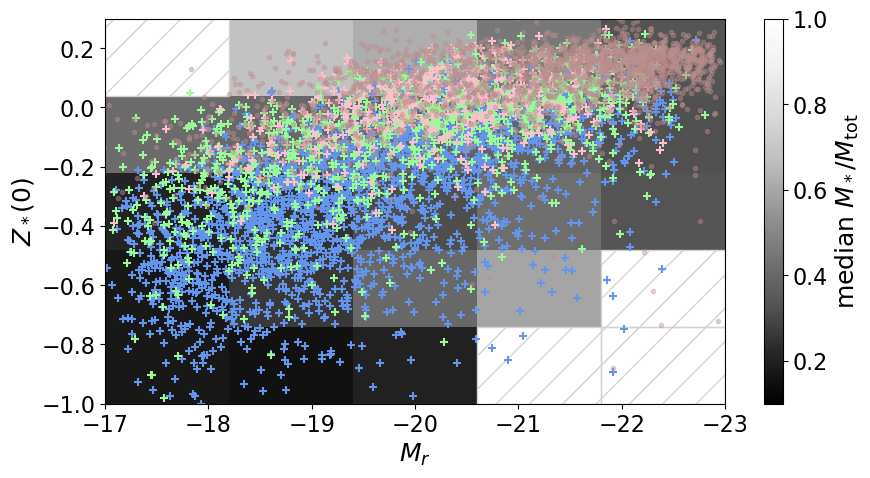

In [403]:
fig, ax = plt.subplots(figsize=(10,5))
im =ax.pcolormesh(mr_bins, z_bins, np.transpose(mstar_mtot_medians), vmin=0.1, vmax=1, cmap='Greys_r')
for i in range(5):
    for j in range(5):

        if np.isnan(mstar_mtot_medians[i][j]):
            # print('fill')
            ax.fill([mr_bins[i], mr_bins[i+1], mr_bins[i+1], mr_bins[i]], 
                     [z_bins[j], z_bins[j], z_bins[j+1], z_bins[j+1]], 'none', hatch='/', edgecolor='lightgrey')
cb = plt.colorbar(im, ax=ax)
cb.set_label(label=r'median $M_*/M_{\rm tot}$', size=18)
im.figure.axes[1].tick_params(axis="y", labelsize=16)
plt.scatter(b_spirals['rabsmag'], b_spirals['stellar_Z_0'], color='cornflowerblue', marker='+')
plt.scatter(g_spirals['rabsmag'], g_spirals['stellar_Z_0'], color='palegreen', marker='+')
plt.scatter(r_spirals['rabsmag'], r_spirals['stellar_Z_0'], color='pink', marker='+')
plt.scatter(ellipticals['rabsmag'], ellipticals['stellar_Z_0'], color='rosybrown', marker='.', alpha=0.4)

ax.tick_params(labelsize=16, axis='both')
plt.xlim(-17,-23)
plt.ylim(-1,0.3)



ax.set_xlabel(r'$M_r$', fontsize=18)
ax.set_ylabel(r'$Z_*(0)$', fontsize=18)
plt.savefig(plot_dir + 'Mr_Zstel_MstarMtot_grid.png', bbox_inches='tight')

In [404]:
HI_spirals['mbar_mtot'] = 10**(HI_spirals_mbar - HI_spirals['M_R90'])
ellipticals['mbar_mtot'] = ellipticals['mstar_mtot']

In [405]:
HI_mags = np.hstack([HI_spirals['rabsmag'], ellipticals['rabsmag']])
mbar_mtot = vstack([HI_spirals['mbar_mtot'], ellipticals['mbar_mtot']])
HI_z_star = np.hstack([HI_spirals['stellar_Z_0'], ellipticals['stellar_Z_0']])

In [406]:
HI_mr_bins = np.linspace(-17, -23, 6)
HI_z_bins = np.linspace(-1, 0.3, 6)
HI_mr_indices = np.digitize(HI_mags, HI_mr_bins, right=True)
HI_z_indices = np.digitize(HI_z_star, HI_z_bins, right=True)

In [407]:
mbar_mtot_medians = np.zeros((5,5))
for i in range(1,6):
    for j in range(1,6):

        mask = np.logical_and(HI_mr_indices == i, HI_z_indices==j)
        data = mbar_mtot['mbar_mtot'][mask]
        if len(data) < 10:
            med = np.nan
        else:
            med = ma.median(data)

        # med = ma.median(data)
        mbar_mtot_medians[i-1][j-1] = med

In [408]:
HI_b_spirals = HI_spirals[HI_spirals['CMD_class'] == 1]
HI_g_spirals = HI_spirals[HI_spirals['CMD_class'] == 2]
HI_r_spirals = HI_spirals[HI_spirals['CMD_class'] == 3]

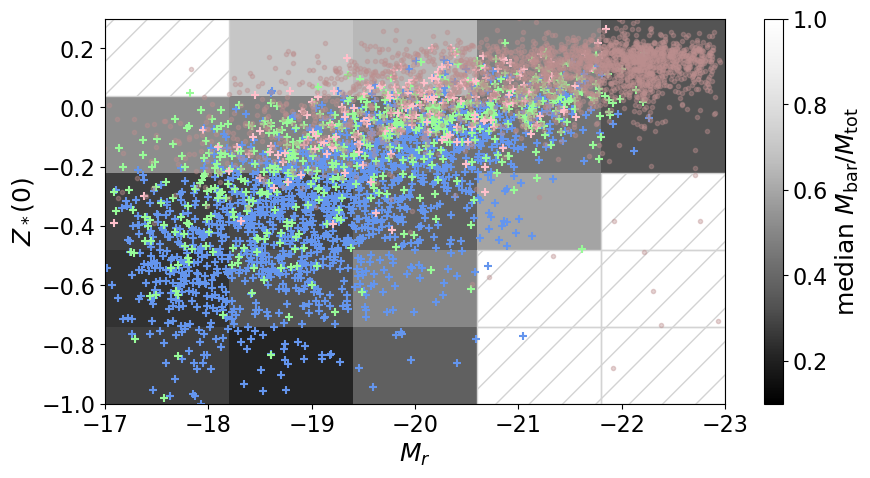

In [409]:
fig, ax = plt.subplots(figsize=(10,5))
im =ax.pcolormesh(HI_mr_bins, HI_z_bins, np.transpose(mbar_mtot_medians), vmin=0.1, vmax=1, cmap='Greys_r')
for i in range(5):
    for j in range(5):

        if np.isnan(mbar_mtot_medians[i][j]):
            # print('fill')
            ax.fill([HI_mr_bins[i], HI_mr_bins[i+1], HI_mr_bins[i+1], HI_mr_bins[i]], 
                     [HI_z_bins[j], HI_z_bins[j], HI_z_bins[j+1], HI_z_bins[j+1]], 'none', hatch='/', edgecolor='lightgrey')
cb = plt.colorbar(im, ax=ax)
cb.set_label(label=r'median $M_{\rm bar}/M_{\rm tot}$', size=18)
im.figure.axes[1].tick_params(axis="y", labelsize=16)
plt.scatter(HI_b_spirals['rabsmag'], HI_b_spirals['stellar_Z_0'], color='cornflowerblue', marker='+')
plt.scatter(HI_g_spirals['rabsmag'], HI_g_spirals['stellar_Z_0'], color='palegreen', marker='+')
plt.scatter(HI_r_spirals['rabsmag'], HI_r_spirals['stellar_Z_0'], color='pink', marker='+')
plt.scatter(ellipticals['rabsmag'], ellipticals['stellar_Z_0'], color='rosybrown', marker='.', alpha=0.4)

ax.tick_params(labelsize=16, axis='both')
plt.xlim(-17,-23)
plt.ylim(-1,0.3)

ax.set_xlabel(r'$M_r$', fontsize=18)
ax.set_ylabel(r'$Z_*(0)$', fontsize=18)
plt.savefig(plot_dir + 'Mr_Zstel_MbarMtot_grid.png', bbox_inches='tight')

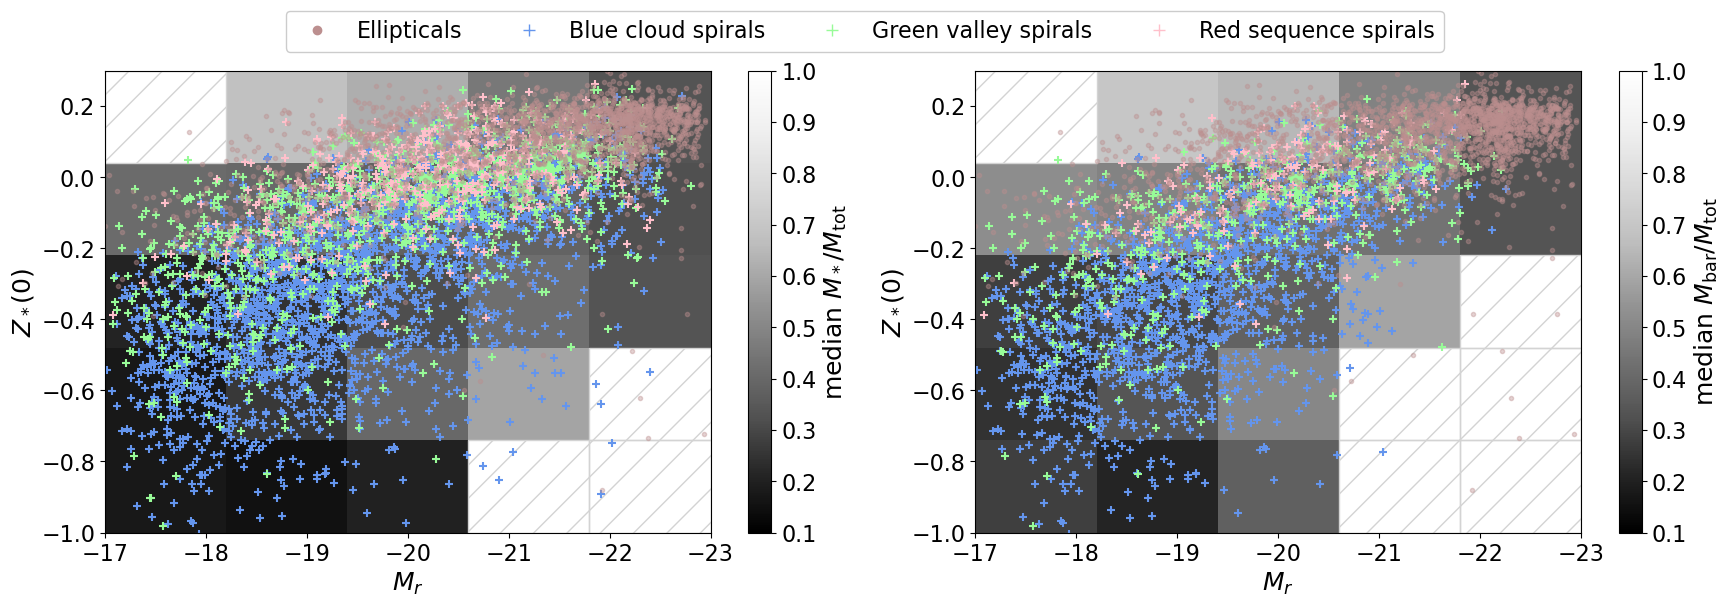

In [410]:
fig, ax = plt.subplots(1,2, figsize=(21,6))

im =ax[0].pcolormesh(mr_bins, z_bins, np.transpose(mstar_mtot_medians), vmin=0.1, vmax=1, cmap='Greys_r')
for i in range(5):
    for j in range(5):

        if np.isnan(mstar_mtot_medians[i][j]):
            # print('fill')
            ax[0].fill([mr_bins[i], mr_bins[i+1], mr_bins[i+1], mr_bins[i]], 
                     [z_bins[j], z_bins[j], z_bins[j+1], z_bins[j+1]], 'none', hatch='/', edgecolor='lightgrey')
cb = plt.colorbar(im, ax=ax[0])
cb.set_label(label=r'median $M_*/M_{\rm tot}$', size=18)
im.figure.axes[2].tick_params(axis="y", labelsize=16)
ax[0].scatter(b_spirals['rabsmag'], b_spirals['stellar_Z_0'], color='cornflowerblue', marker='+')
ax[0].scatter(g_spirals['rabsmag'], g_spirals['stellar_Z_0'], color='palegreen', marker='+')
ax[0].scatter(r_spirals['rabsmag'], r_spirals['stellar_Z_0'], color='pink', marker='+')
ax[0].scatter(ellipticals['rabsmag'], ellipticals['stellar_Z_0'], color='rosybrown', marker='.', alpha=0.4)

ax[0].tick_params(labelsize=16, axis='both')
ax[0].set_xlim(-17,-23)
ax[0].set_ylim(-1,0.3)



ax[0].set_xlabel(r'$M_r$', fontsize=18)
ax[0].set_ylabel(r'$Z_*(0)$', fontsize=18)


im =ax[1].pcolormesh(HI_mr_bins, HI_z_bins, np.transpose(mbar_mtot_medians), vmin=0.1, vmax=1, cmap='Greys_r')
for i in range(5):
    for j in range(5):

        if np.isnan(mbar_mtot_medians[i][j]):
            # print('fill')
            ax[1].fill([HI_mr_bins[i], HI_mr_bins[i+1], HI_mr_bins[i+1], HI_mr_bins[i]], 
                     [HI_z_bins[j], HI_z_bins[j], HI_z_bins[j+1], HI_z_bins[j+1]], 'none', hatch='/', edgecolor='lightgrey')
cb = plt.colorbar(im, ax=ax[1])
cb.set_label(label=r'median $M_{\rm bar}/M_{\rm tot}$', size=18)
im.figure.axes[3].tick_params(axis="y", labelsize=16)
ax[1].scatter(HI_b_spirals['rabsmag'], HI_b_spirals['stellar_Z_0'], color='cornflowerblue', marker='+')
ax[1].scatter(HI_g_spirals['rabsmag'], HI_g_spirals['stellar_Z_0'], color='palegreen', marker='+')
ax[1].scatter(HI_r_spirals['rabsmag'], HI_r_spirals['stellar_Z_0'], color='pink', marker='+')
ax[1].scatter(ellipticals['rabsmag'], ellipticals['stellar_Z_0'], color='rosybrown', marker='.', alpha=0.4)

ax[1].tick_params(labelsize=16, axis='both')
plt.xlim(-17,-23)
plt.ylim(-1,0.3)

ax[1].set_xlabel(r'$M_r$', fontsize=18)
ax[1].set_ylabel(r'$Z_*(0)$', fontsize=18)

legend_elements = [Line2D([0], [0], marker='o', color='w', label='Ellipticals',
                          markeredgecolor='rosybrown', markerfacecolor='rosybrown', markersize=6),
                   Line2D([0], [0], marker='+', color='w', label='Blue cloud spirals',
                          markeredgecolor='cornflowerblue', markerfacecolor='cornflowerblue', markersize=8),
                   Line2D([0], [0], marker='+', color='w', label='Green valley spirals',
                          markeredgecolor='palegreen', markerfacecolor='palegreen', markersize=8),
                   Line2D([0], [0], marker='+', color='w', label='Red sequence spirals',
                          markeredgecolor='pink', markerfacecolor='pink', markersize=8),]

fig.legend(handles=legend_elements, loc='upper center', framealpha=1, ncols=4, fontsize=16)
fig.subplots_adjust(wspace=0.15,)
# fig.legend(handles=legend_elements, fontsize=14)

# plt.savefig(plot_dir + 'Mr_Zstel_MbarMtot_grid.png', bbox_inches='tight')

# plt.savefig(plot_dir + 'Mr_Zstel_MstarMtot_grid.png', bbox_inches='tight')

plt.savefig(plot_dir + 'Mr_Zstel_ratio_grids.png', bbox_inches='tight')

## split into mr bins and then plot z vs ratio

In [411]:
bs_indices = np.digitize(b_spirals['rabsmag'], mr_bins, right=True)
gs_indices = np.digitize(g_spirals['rabsmag'], mr_bins, right=True)
rs_indices = np.digitize(r_spirals['rabsmag'], mr_bins, right=True)
e_indices = np.digitize(ellipticals['rabsmag'], mr_bins, right=True)

In [412]:
for i in range(1, len(mr_bins)):
    plt.scatter(b_spirals['stellar_Z_0'][bs_indices==i], b_spirals['mstar_mtot'][bs_indices==i], marker='+', color='cornflowerblue')
    plt.scatter(g_spirals['stellar_Z_0'][gs_indices==i], g_spirals['mstar_mtot'][gs_indices==i], marker='+', color='palegreen')
    plt.scatter(r_spirals['stellar_Z_0'][rs_indices==i], r_spirals['mstar_mtot'][rs_indices==i], marker='+', color='pink')
    plt.scatter(ellipticals['stellar_Z_0'][e_indices==i], ellipticals['mstar_mtot'][e_indices==i], marker='.', color='rosybrown')
    
    plt.xlabel(r'$Z_*(0)$', size=18)
    plt.ylabel(r'$M_*/M_{\rm tot}$', size=18)
    plt.tick_params(labelsize=16)

    if i == len(mr_bins) - 1:
    
        legend_elements = [Line2D([0], [0], marker='o', color='w', label='Ellipticals',
                                  markeredgecolor='rosybrown', markerfacecolor='rosybrown', markersize=6),
                           Line2D([0], [0], marker='+', color='w', label='Blue cloud spirals',
                                  markeredgecolor='cornflowerblue', markerfacecolor='cornflowerblue', markersize=8),
                           Line2D([0], [0], marker='+', color='w', label='Green valley spirals',
                                  markeredgecolor='palegreen', markerfacecolor='palegreen', markersize=8),
                           Line2D([0], [0], marker='+', color='w', label='Red sequence spirals',
                                  markeredgecolor='pink', markerfacecolor='pink', markersize=8),]
        
        plt.legend(handles=legend_elements, fontsize=14)
    
    plt.xlim(-1,0.3)
    plt.ylim(0,1)

    a=mr_bins[i-1]
    b=mr_bins[i]
    plt.title(rf'{a} $<M_r<$ {b}', fontsize=18)

    plt.savefig(plot_dir + 'stelz_mstarmtot_mrbin_' + str(i) + '.png', bbox_inches='tight')

    plt.cla()
    plt.clf()
    plt.close()

In [413]:
HI_bs_indices = np.digitize(HI_b_spirals['rabsmag'], mr_bins, right=True)
HI_gs_indices = np.digitize(HI_g_spirals['rabsmag'], mr_bins, right=True)
HI_rs_indices = np.digitize(HI_r_spirals['rabsmag'], mr_bins, right=True)
e_indices = np.digitize(ellipticals['rabsmag'], mr_bins, right=True)

In [414]:
for i in range(1, len(mr_bins)):
    plt.scatter(HI_b_spirals['stellar_Z_0'][HI_bs_indices==i], HI_b_spirals['mbar_mtot'][HI_bs_indices==i], marker='+', color='cornflowerblue')
    plt.scatter(HI_g_spirals['stellar_Z_0'][HI_gs_indices==i], HI_g_spirals['mbar_mtot'][HI_gs_indices==i], marker='+', color='palegreen')
    plt.scatter(HI_r_spirals['stellar_Z_0'][HI_rs_indices==i], HI_r_spirals['mbar_mtot'][HI_rs_indices==i], marker='+', color='pink')
    plt.scatter(ellipticals['stellar_Z_0'][e_indices==i], ellipticals['mstar_mtot'][e_indices==i], marker='.', color='rosybrown')


    num_pts = len(HI_b_spirals['stellar_Z_0'][HI_bs_indices==i]) + len(HI_g_spirals['stellar_Z_0'][HI_gs_indices==i]) +\
                len(HI_r_spirals['stellar_Z_0'][HI_rs_indices==i]) + len(ellipticals['stellar_Z_0'][e_indices==i])
    
    centroid_x = (np.sum(HI_b_spirals['stellar_Z_0'][HI_bs_indices==i]) + np.sum(HI_g_spirals['stellar_Z_0'][HI_gs_indices==i]) + 
                  np.sum(HI_r_spirals['stellar_Z_0'][HI_rs_indices==i]) + np.sum(ellipticals['stellar_Z_0'][e_indices==i])) / num_pts
    centroid_y = (np.sum(HI_b_spirals['mbar_mtot'][HI_bs_indices==i]) + np.sum(HI_g_spirals['mbar_mtot'][HI_gs_indices==i]) + 
                  np.sum(HI_r_spirals['mbar_mtot'][HI_rs_indices==i]) + np.sum(ellipticals['mstar_mtot'][e_indices==i])) / num_pts

    plt.scatter(centroid_x, centroid_y, marker='*', s=40, color='yellow', edgecolor='k')
    print(centroid_x, centroid_y)
    
    plt.xlabel(r'$Z_*(0)$', size=18)
    plt.ylabel(r'$M_{\rm bar}/M_{\rm tot}$', size=18)
    plt.tick_params(labelsize=16)

    if i == len(mr_bins) - 1:
    
        legend_elements = [Line2D([0], [0], marker='o', color='w', label='Ellipticals',
                                  markeredgecolor='rosybrown', markerfacecolor='rosybrown', markersize=6),
                           Line2D([0], [0], marker='+', color='w', label='Blue cloud spirals',
                                  markeredgecolor='cornflowerblue', markerfacecolor='cornflowerblue', markersize=8),
                           Line2D([0], [0], marker='+', color='w', label='Green valley spirals',
                                  markeredgecolor='palegreen', markerfacecolor='palegreen', markersize=8),
                           Line2D([0], [0], marker='+', color='w', label='Red sequence spirals',
                                  markeredgecolor='pink', markerfacecolor='pink', markersize=8),]
        
        plt.legend(handles=legend_elements, fontsize=14)
    
    plt.xlim(-1,0.3)
    plt.ylim(0,1)

    a=mr_bins[i-1]
    b=mr_bins[i]
    plt.title(rf'{a} $<M_r<$ {b}', fontsize=18)

    plt.savefig(plot_dir + 'stelz_mbarmtot_mrbin_' + str(i) + '.png', bbox_inches='tight')

    plt.cla()
    plt.clf()
    plt.close()

-0.1615976698232589 0.5097622605446465
0.0075841746957552875 0.6198886917060091
0.018839622187430974 0.667553666871464
0.06769901580280943 0.5823910400500728
0.130735185606767 0.35230594558817324


## void vs wall

vflag 0 = wall, 1 = void, 2 = edge galaxy, 9 = outside survey footprint

### stellar metallicity of void and wall galaxies

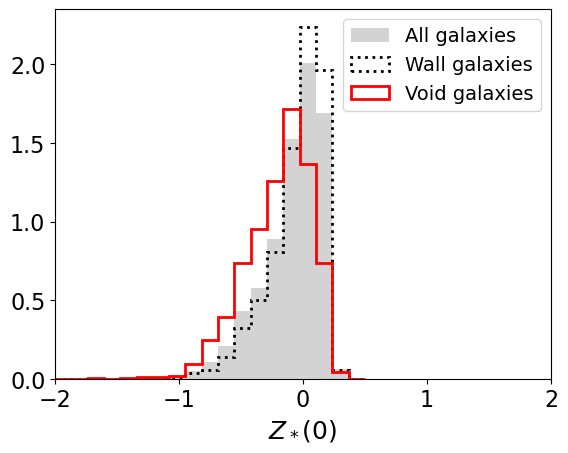

In [415]:
plt.hist(good_stelz['stellar_Z_0'], color='lightgrey', bins=np.linspace(-2,0.5, 20), label='All galaxies', density=True)
plt.hist(good_stelz[good_stelz['vflag_VF'] == 0]['stellar_Z_0'], bins=np.linspace(-2,0.5, 20),
         histtype='step', color='k', linestyle=':',lw=2,
         label='Wall galaxies', density=True)
plt.hist(good_stelz[good_stelz['vflag_VF'] == 1]['stellar_Z_0'], bins=np.linspace(-2,0.5, 20),
         histtype='step', color='r', linestyle='-', lw=2,
         label='Void galaxies', density=True)
plt.legend(fontsize=14)

plt.xlabel(r'$Z_*(0)$', fontsize=18)
plt.tick_params(axis='both', labelsize=16)
plt.xlim(-2,2)

plt.savefig(plot_dir + '/void_wall/stelz_hist.png', bbox_inches='tight')

### mstar/mtot

In [416]:
vflag_se = vstack([good_spirals['vflag_VF'], ellipticals['vflag_VF']])

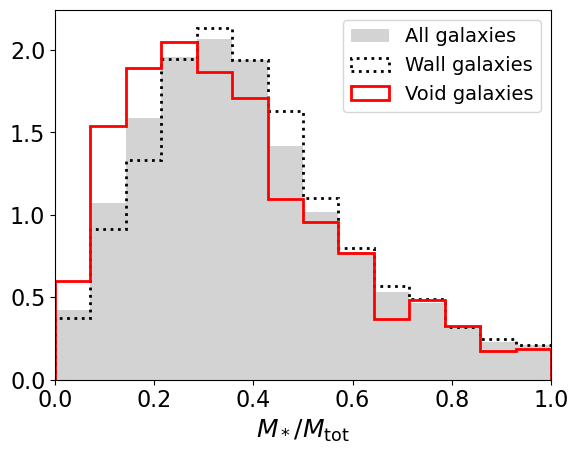

In [417]:
plt.hist(mstar_mtot['mstar_mtot'], color='lightgrey', bins=np.linspace(0,1, 15), label='All galaxies', density=True)
plt.hist(mstar_mtot['mstar_mtot'][vflag_se['vflag_VF'] == 0], bins=np.linspace(0,1, 15),
         histtype='step', color='k', linestyle=':',lw=2,
         label='Wall galaxies', density=True)
plt.hist(mstar_mtot['mstar_mtot'][vflag_se['vflag_VF'] == 1], bins=np.linspace(0,1, 15),
         histtype='step', color='r', linestyle='-',lw=2,
         label='Void galaxies', density=True)
plt.legend(fontsize=14)

plt.xlabel(r'$M_*/M_{\rm tot}$', fontsize=18)
plt.tick_params(axis='both', labelsize=16)
plt.xlim(0,1)
plt.savefig(plot_dir + '/void_wall/mstarmtot_hist.png', bbox_inches='tight')

### mbar/mtot

In [418]:
vflag_HIse = vstack([HI_spirals['vflag_VF'], ellipticals['vflag_VF']])

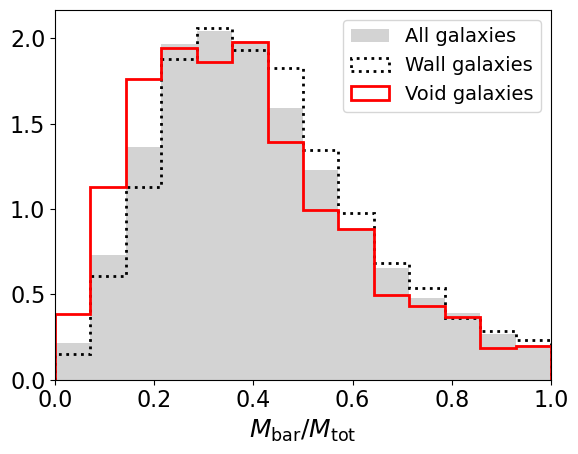

In [419]:
plt.hist(mbar_mtot['mbar_mtot'], color='lightgrey', bins=np.linspace(0,1, 15), label='All galaxies', density=True)
plt.hist(mbar_mtot['mbar_mtot'][vflag_HIse['vflag_VF'] == 0], bins=np.linspace(0,1, 15),
         histtype='step', color='k', linestyle=':',lw=2,
         label='Wall galaxies', density=True)
plt.hist(mbar_mtot['mbar_mtot'][vflag_HIse['vflag_VF'] == 1], bins=np.linspace(0,1, 15),
         histtype='step', color='r', linestyle='-',lw=2,
         label='Void galaxies', density=True)
plt.legend(fontsize=14)

plt.xlabel(r'$M_{\rm bar}/M_{\rm tot}$', fontsize=18)
plt.tick_params(axis='both', labelsize=16)
plt.xlim(0,1)
plt.savefig(plot_dir + '/void_wall/mbarmtot_hist.png', bbox_inches='tight')

### rabsmag

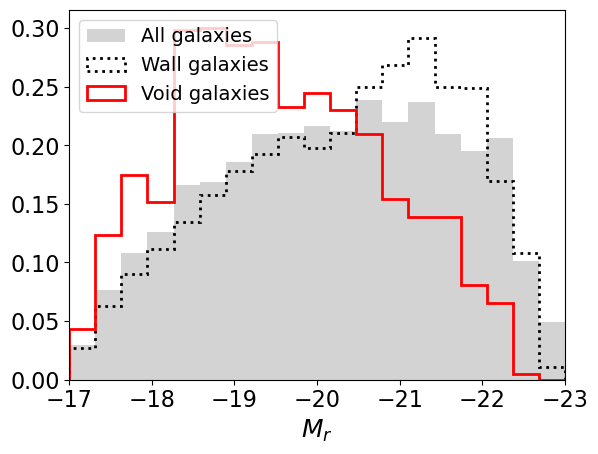

In [420]:
plt.hist(good_stelz['rabsmag'], color='lightgrey', bins=np.linspace(-23,-17, 20), label='All galaxies', density=True)
plt.hist(good_stelz[good_stelz['vflag_VF'] == 0]['rabsmag'], bins=np.linspace(-23,-17, 20),
         histtype='step', color='k', linestyle=':',lw=2,
         label='Wall galaxies', density=True)
plt.hist(good_stelz[good_stelz['vflag_VF'] == 1]['rabsmag'], bins=np.linspace(-23,-17, 20),
         histtype='step', color='r', linestyle='-', lw=2,
         label='Void galaxies', density=True)
plt.legend(fontsize=14)

plt.xlabel(r'$M_r$', fontsize=18)
plt.tick_params(axis='both', labelsize=16)
plt.xlim(-17,-23)
plt.savefig(plot_dir + '/void_wall/mr_hist.png', bbox_inches='tight')

### grid plots w void vs wall

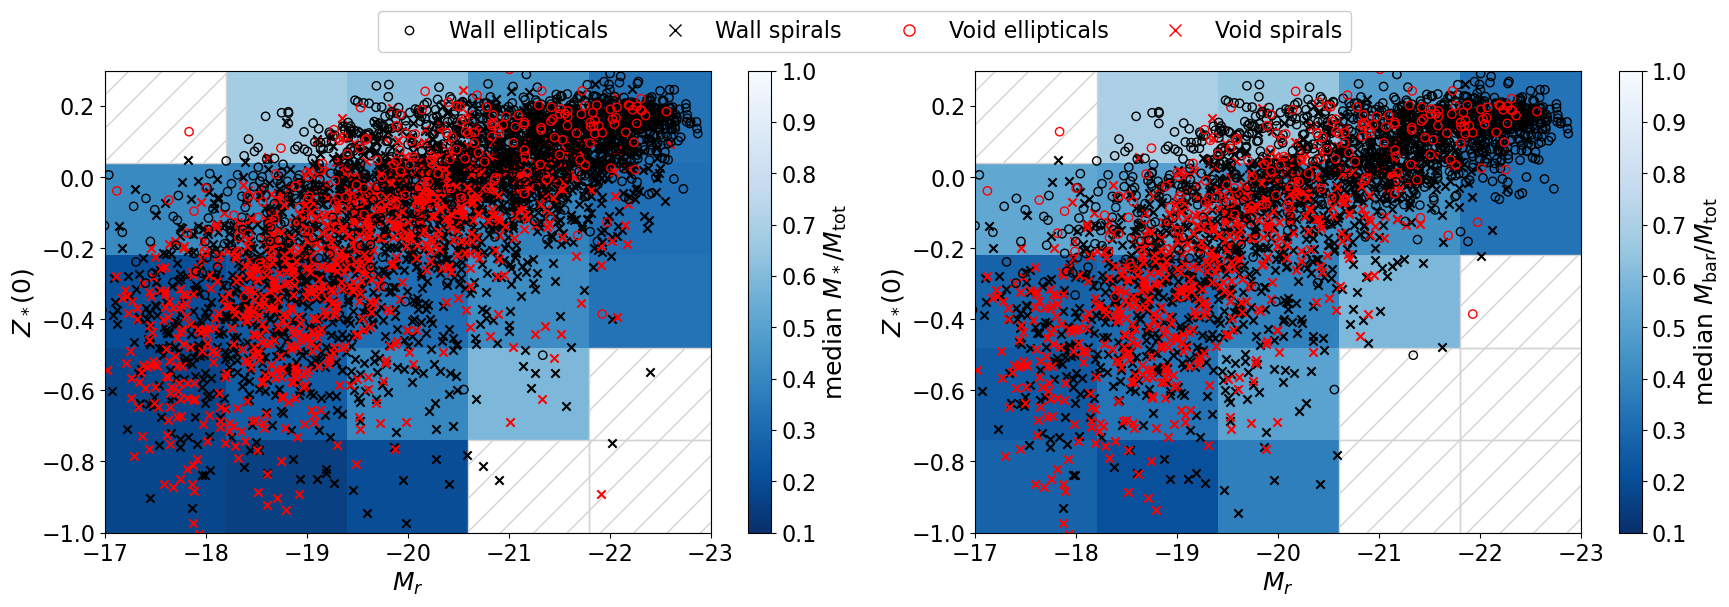

In [421]:
fig, ax = plt.subplots(1,2, figsize=(21,6))

im =ax[0].pcolormesh(mr_bins, z_bins, np.transpose(mstar_mtot_medians), vmin=0.1, vmax=1, cmap='Blues_r')
for i in range(5):
    for j in range(5):

        if np.isnan(mstar_mtot_medians[i][j]):
            # print('fill')
            ax[0].fill([mr_bins[i], mr_bins[i+1], mr_bins[i+1], mr_bins[i]], 
                     [z_bins[j], z_bins[j], z_bins[j+1], z_bins[j+1]], 'none', hatch='/', edgecolor='lightgrey')
cb = plt.colorbar(im, ax=ax[0])
cb.set_label(label=r'median $M_*/M_{\rm tot}$', size=18)
im.figure.axes[2].tick_params(axis="y", labelsize=16)
# ax[0].scatter(b_spirals['rabsmag'], b_spirals['stellar_Z_0'], color='cornflowerblue', marker='+')
# ax[0].scatter(g_spirals['rabsmag'], g_spirals['stellar_Z_0'], color='palegreen', marker='+')
# ax[0].scatter(r_spirals['rabsmag'], r_spirals['stellar_Z_0'], color='pink', marker='+')
# ax[0].scatter(ellipticals['rabsmag'], ellipticals['stellar_Z_0'], color='rosybrown', marker='.', alpha=0.4)
ax[0].scatter(good_spirals[good_spirals['vflag_VF']==0]['rabsmag'], good_spirals[good_spirals['vflag_VF']==0]['stellar_Z_0'],
              marker='x', color='k')
ax[0].scatter(good_spirals[good_spirals['vflag_VF']==1]['rabsmag'], good_spirals[good_spirals['vflag_VF']==1]['stellar_Z_0'],
              marker='x', color='r')
ax[0].scatter(ellipticals[ellipticals['vflag_VF']==0]['rabsmag'], ellipticals[ellipticals['vflag_VF']==0]['stellar_Z_0'],
              marker='o', color='k', facecolor='none')
ax[0].scatter(ellipticals[ellipticals['vflag_VF']==1]['rabsmag'], ellipticals[ellipticals['vflag_VF']==1]['stellar_Z_0'],
              marker='o', color='r', facecolor='none')

ax[0].tick_params(labelsize=16, axis='both')
ax[0].set_xlim(-17,-23)
ax[0].set_ylim(-1,0.3)



ax[0].set_xlabel(r'$M_r$', fontsize=18)
ax[0].set_ylabel(r'$Z_*(0)$', fontsize=18)


im =ax[1].pcolormesh(HI_mr_bins, HI_z_bins, np.transpose(mbar_mtot_medians), vmin=0.1, vmax=1, cmap='Blues_r')
for i in range(5):
    for j in range(5):

        if np.isnan(mbar_mtot_medians[i][j]):
            # print('fill')
            ax[1].fill([HI_mr_bins[i], HI_mr_bins[i+1], HI_mr_bins[i+1], HI_mr_bins[i]], 
                     [HI_z_bins[j], HI_z_bins[j], HI_z_bins[j+1], HI_z_bins[j+1]], 'none', hatch='/', edgecolor='lightgrey')
cb = plt.colorbar(im, ax=ax[1])
cb.set_label(label=r'median $M_{\rm bar}/M_{\rm tot}$', size=18)
im.figure.axes[3].tick_params(axis="y", labelsize=16)
# ax[1].scatter(HI_b_spirals['rabsmag'], HI_b_spirals['stellar_Z_0'], color='cornflowerblue', marker='+')
# ax[1].scatter(HI_g_spirals['rabsmag'], HI_g_spirals['stellar_Z_0'], color='palegreen', marker='+')
# ax[1].scatter(HI_r_spirals['rabsmag'], HI_r_spirals['stellar_Z_0'], color='pink', marker='+')
# ax[1].scatter(ellipticals['rabsmag'], ellipticals['stellar_Z_0'], color='rosybrown', marker='.', alpha=0.4)

ax[1].scatter(HI_spirals[HI_spirals['vflag_VF']==0]['rabsmag'], HI_spirals[HI_spirals['vflag_VF']==0]['stellar_Z_0'],
              marker='x', color='k')
ax[1].scatter(HI_spirals[HI_spirals['vflag_VF']==1]['rabsmag'], HI_spirals[HI_spirals['vflag_VF']==1]['stellar_Z_0'],
              marker='x', color='r')
ax[1].scatter(ellipticals[ellipticals['vflag_VF']==0]['rabsmag'], ellipticals[ellipticals['vflag_VF']==0]['stellar_Z_0'],
              marker='o', color='k', facecolor='none')
ax[1].scatter(ellipticals[ellipticals['vflag_VF']==1]['rabsmag'], ellipticals[ellipticals['vflag_VF']==1]['stellar_Z_0'],
              marker='o', color='r', facecolor='none')

ax[1].tick_params(labelsize=16, axis='both')
plt.xlim(-17,-23)
plt.ylim(-1,0.3)

ax[1].set_xlabel(r'$M_r$', fontsize=18)
ax[1].set_ylabel(r'$Z_*(0)$', fontsize=18)

legend_elements = [Line2D([0], [0], marker='o', color='w', label='Wall ellipticals',
                          markeredgecolor='k', markerfacecolor='none', markersize=6),
                   Line2D([0], [0], marker='x', color='w', label='Wall spirals',
                          markeredgecolor='k', markerfacecolor='k', markersize=8),
                   Line2D([0], [0], marker='o', color='w', label='Void ellipticals',
                          markeredgecolor='r', markerfacecolor='none', markersize=8),
                   Line2D([0], [0], marker='x', color='w', label='Void spirals',
                          markeredgecolor='r', markerfacecolor='r', markersize=8),]

fig.legend(handles=legend_elements, loc='upper center', framealpha=1, ncols=4, fontsize=16)
fig.subplots_adjust(wspace=0.15,)
# fig.legend(handles=legend_elements, fontsize=14)

# plt.savefig(plot_dir + 'Mr_Zstel_MbarMtot_grid.png', bbox_inches='tight')

# plt.savefig(plot_dir + 'Mr_Zstel_MstarMtot_grid.png', bbox_inches='tight')

# plt.savefig(plot_dir + 'Mr_Zstel_ratio_grids.png', bbox_inches='tight')

plt.savefig(plot_dir + '/void_wall/grids.png', bbox_inches='tight')

### get void and wall counts by type

In [422]:
print('void ellipticals/ellipticals', len(ellipticals[ellipticals['vflag_VF']==1])/len(ellipticals))
print('wall ellipticals/ellipticals', len(ellipticals[ellipticals['vflag_VF']==0])/len(ellipticals))

print('void blue spirals/blue spirals', len(b_spirals[b_spirals['vflag_VF']==1])/len(b_spirals))
print('wall blue spirals/blue spirals', len(b_spirals[b_spirals['vflag_VF']==0])/len(b_spirals))

print('void blue spirals with HI/blue spirals with HI', len(HI_b_spirals[HI_b_spirals['vflag_VF']==1])/len(HI_b_spirals))
print('wall blue spirals with HI/blue spirals with HI', len(HI_b_spirals[HI_b_spirals['vflag_VF']==0])/len(HI_b_spirals))


print('void green spirals/green spirals', len(g_spirals[g_spirals['vflag_VF']==1])/len(g_spirals))
print('wall green spirals/green spirals', len(g_spirals[g_spirals['vflag_VF']==0])/len(g_spirals))

print('void green spirals with HI/green spirals with HI', len(HI_g_spirals[HI_g_spirals['vflag_VF']==1])/len(HI_g_spirals))
print('wall green spirals with HI/green spirals with HI', len(HI_g_spirals[HI_g_spirals['vflag_VF']==0])/len(HI_g_spirals))


print('void red spirals/red spirals', len(r_spirals[r_spirals['vflag_VF']==1])/len(r_spirals))
print('wall red spirals/red spirals', len(r_spirals[r_spirals['vflag_VF']==0])/len(r_spirals))

print('void red spirals with HI/red spirals with HI', len(HI_r_spirals[HI_r_spirals['vflag_VF']==1])/len(HI_r_spirals))
print('wall red spirals with HI/red spirals with HI', len(HI_r_spirals[HI_r_spirals['vflag_VF']==0])/len(HI_r_spirals))

void ellipticals/ellipticals 0.07810499359795134
wall ellipticals/ellipticals 0.5096030729833547
void blue spirals/blue spirals 0.2326858108108108
wall blue spirals/blue spirals 0.4066722972972973
void blue spirals with HI/blue spirals with HI 0.2558252427184466
wall blue spirals with HI/blue spirals with HI 0.38980582524271845
void green spirals/green spirals 0.1493288590604027
wall green spirals/green spirals 0.47818791946308725
void green spirals with HI/green spirals with HI 0.15532544378698224
wall green spirals with HI/green spirals with HI 0.45710059171597633
void red spirals/red spirals 0.13733905579399142
wall red spirals/red spirals 0.5257510729613734
void red spirals with HI/red spirals with HI 0.13793103448275862
wall red spirals with HI/red spirals with HI 0.47783251231527096


### mr vs mstarmtot by type

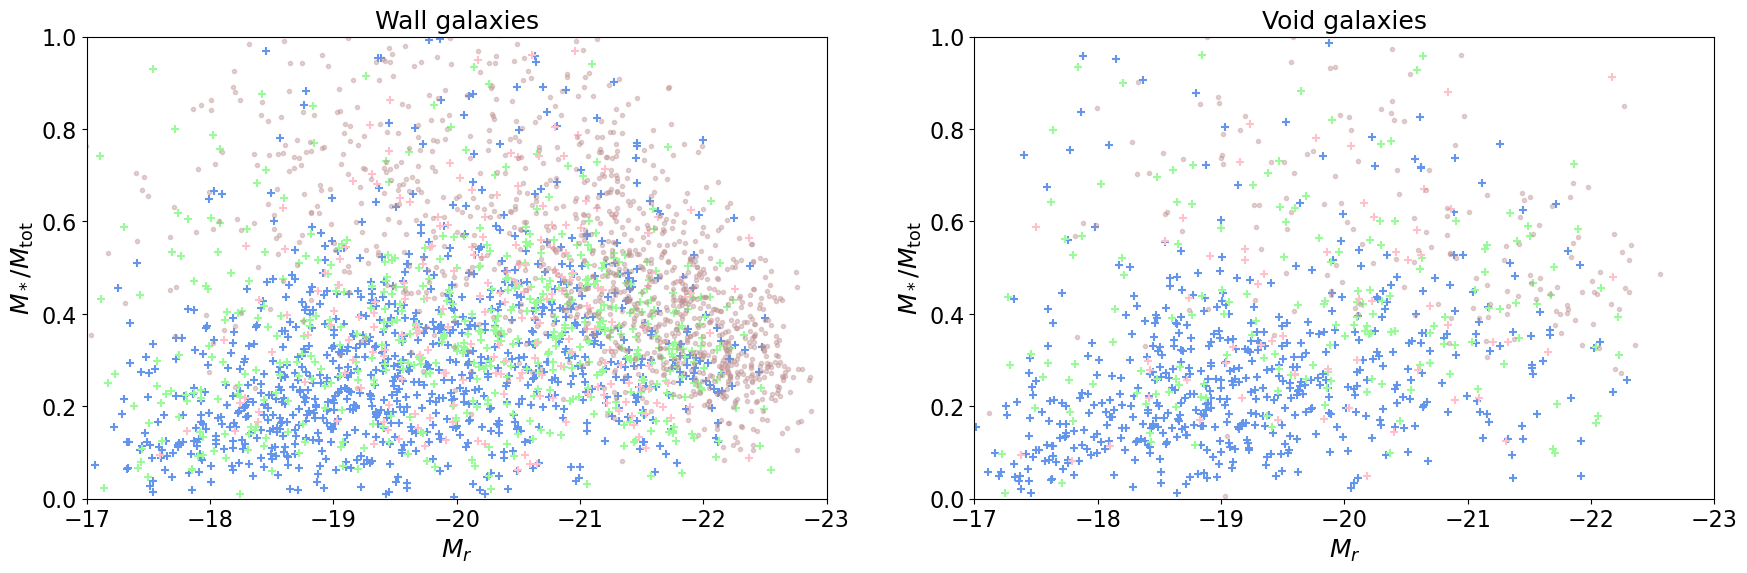

In [423]:
fig, ax = plt.subplots(1,2, figsize=(21,6))

ax[0].scatter(b_spirals[b_spirals['vflag_VF'] == 0]['rabsmag'], b_spirals[b_spirals['vflag_VF'] == 0]['mstar_mtot'], color='cornflowerblue', marker='+')
ax[0].scatter(g_spirals[g_spirals['vflag_VF'] == 0]['rabsmag'], g_spirals[g_spirals['vflag_VF'] == 0]['mstar_mtot'], color='palegreen', marker='+')
ax[0].scatter(r_spirals[r_spirals['vflag_VF'] == 0]['rabsmag'], r_spirals[r_spirals['vflag_VF'] == 0]['mstar_mtot'], color='pink', marker='+')
ax[0].scatter(ellipticals[ellipticals['vflag_VF'] == 0]['rabsmag'], ellipticals[ellipticals['vflag_VF'] == 0]['mstar_mtot'], color='rosybrown', marker='.', alpha=0.4)



ax[1].scatter(b_spirals[b_spirals['vflag_VF'] == 1]['rabsmag'], b_spirals[b_spirals['vflag_VF'] == 1]['mstar_mtot'], color='cornflowerblue', marker='+')
ax[1].scatter(g_spirals[g_spirals['vflag_VF'] == 1]['rabsmag'], g_spirals[g_spirals['vflag_VF'] == 1]['mstar_mtot'], color='palegreen', marker='+')
ax[1].scatter(r_spirals[r_spirals['vflag_VF'] == 1]['rabsmag'], r_spirals[r_spirals['vflag_VF'] == 1]['mstar_mtot'], color='pink', marker='+')
ax[1].scatter(ellipticals[ellipticals['vflag_VF'] == 1]['rabsmag'], ellipticals[ellipticals['vflag_VF'] == 1]['mstar_mtot'], color='rosybrown', marker='.', alpha=0.4)

for i in range(2):
    ax[i].tick_params(labelsize=16, axis='both')
    ax[i].set_xlim(-17,-23)
    ax[i].set_ylim(0,1)
    ax[i].set_xlabel(r'$M_r$', fontsize=18)
    ax[i].set_ylabel(r'$M_*/M_{\rm tot}$', fontsize=18)

ax[0].set_title('Wall galaxies', fontsize=18)

ax[1].set_title('Void galaxies', fontsize=18)

fig.savefig(plot_dir + '/void_wall/mr_mstarmtot_voidwall.png', bbox_inches='tight')

### mbar/mtot

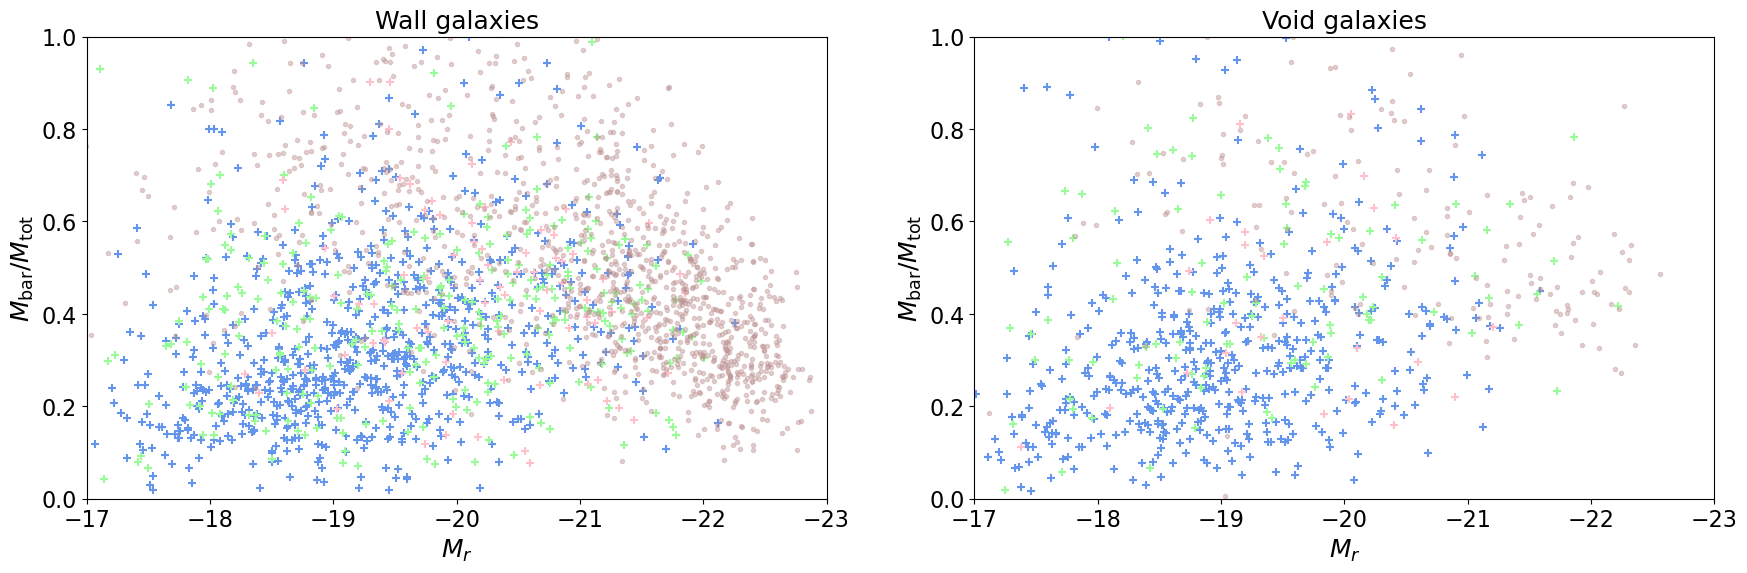

In [424]:
fig, ax = plt.subplots(1,2, figsize=(21,6))

ax[0].scatter(HI_b_spirals[HI_b_spirals['vflag_VF'] == 0]['rabsmag'], HI_b_spirals[HI_b_spirals['vflag_VF'] == 0]['mbar_mtot'], color='cornflowerblue', marker='+')
ax[0].scatter(HI_g_spirals[HI_g_spirals['vflag_VF'] == 0]['rabsmag'], HI_g_spirals[HI_g_spirals['vflag_VF'] == 0]['mbar_mtot'], color='palegreen', marker='+')
ax[0].scatter(HI_r_spirals[HI_r_spirals['vflag_VF'] == 0]['rabsmag'], HI_r_spirals[HI_r_spirals['vflag_VF'] == 0]['mbar_mtot'], color='pink', marker='+')
ax[0].scatter(ellipticals[ellipticals['vflag_VF'] == 0]['rabsmag'], ellipticals[ellipticals['vflag_VF'] == 0]['mstar_mtot'], color='rosybrown', marker='.', alpha=0.4)



ax[1].scatter(HI_b_spirals[HI_b_spirals['vflag_VF'] == 1]['rabsmag'], HI_b_spirals[HI_b_spirals['vflag_VF'] == 1]['mbar_mtot'], color='cornflowerblue', marker='+')
ax[1].scatter(HI_g_spirals[HI_g_spirals['vflag_VF'] == 1]['rabsmag'], HI_g_spirals[HI_g_spirals['vflag_VF'] == 1]['mbar_mtot'], color='palegreen', marker='+')
ax[1].scatter(HI_r_spirals[HI_r_spirals['vflag_VF'] == 1]['rabsmag'], HI_r_spirals[HI_r_spirals['vflag_VF'] == 1]['mbar_mtot'], color='pink', marker='+')
ax[1].scatter(ellipticals[ellipticals['vflag_VF'] == 1]['rabsmag'], ellipticals[ellipticals['vflag_VF'] == 1]['mstar_mtot'], color='rosybrown', marker='.', alpha=0.4)

for i in range(2):
    ax[i].tick_params(labelsize=16, axis='both')
    ax[i].set_xlim(-17,-23)
    ax[i].set_ylim(0,1)
    ax[i].set_xlabel(r'$M_r$', fontsize=18)
    ax[i].set_ylabel(r'$M_{\rm bar}/M_{\rm tot}$', fontsize=18)

ax[0].set_title('Wall galaxies', fontsize=18)

ax[1].set_title('Void galaxies', fontsize=18)

fig.savefig(plot_dir + '/void_wall/mr_mbarmtot_voidwall.png', bbox_inches='tight')

### z0 vs mstarmtot

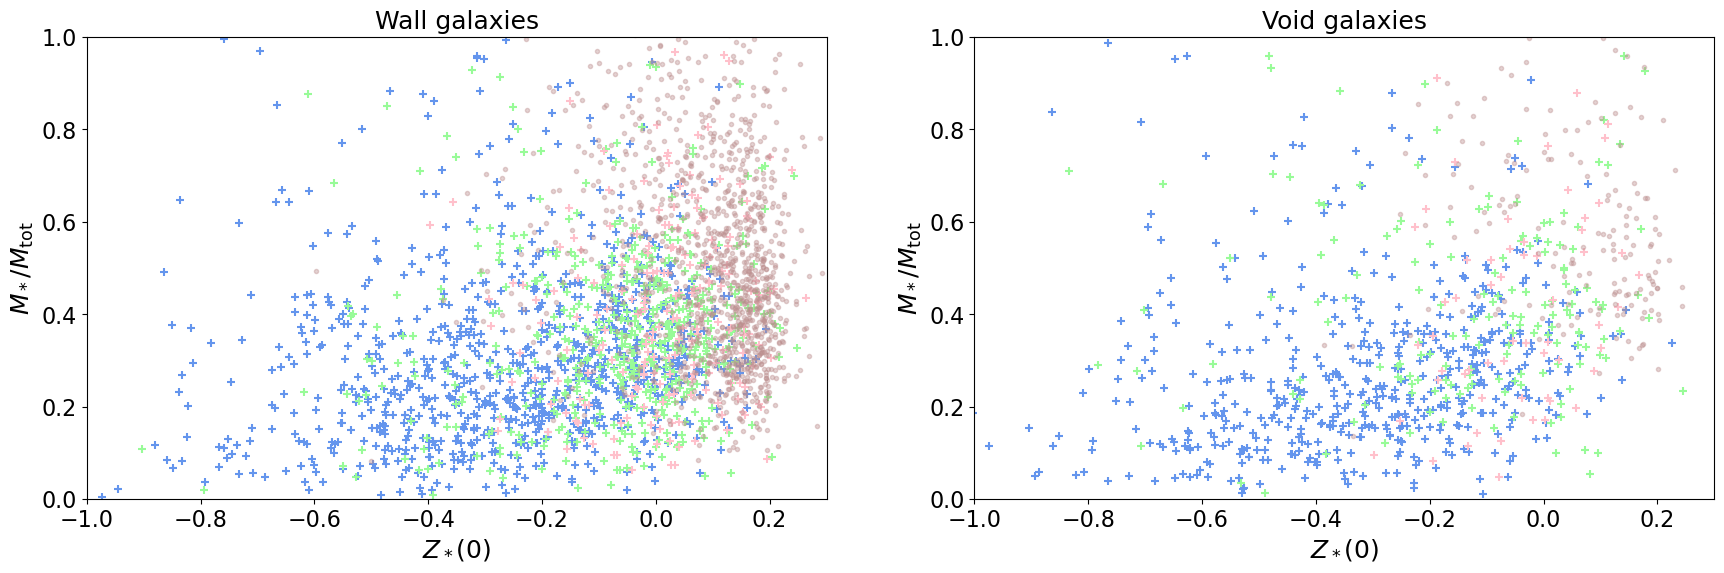

In [425]:
fig, ax = plt.subplots(1,2, figsize=(21,6))

ax[0].scatter(b_spirals[b_spirals['vflag_VF'] == 0]['stellar_Z_0'], b_spirals[b_spirals['vflag_VF'] == 0]['mstar_mtot'], color='cornflowerblue', marker='+')
ax[0].scatter(g_spirals[g_spirals['vflag_VF'] == 0]['stellar_Z_0'], g_spirals[g_spirals['vflag_VF'] == 0]['mstar_mtot'], color='palegreen', marker='+')
ax[0].scatter(r_spirals[r_spirals['vflag_VF'] == 0]['stellar_Z_0'], r_spirals[r_spirals['vflag_VF'] == 0]['mstar_mtot'], color='pink', marker='+')
ax[0].scatter(ellipticals[ellipticals['vflag_VF'] == 0]['stellar_Z_0'], ellipticals[ellipticals['vflag_VF'] == 0]['mstar_mtot'], color='rosybrown', marker='.', alpha=0.4)



ax[1].scatter(b_spirals[b_spirals['vflag_VF'] == 1]['stellar_Z_0'], b_spirals[b_spirals['vflag_VF'] == 1]['mstar_mtot'], color='cornflowerblue', marker='+')
ax[1].scatter(g_spirals[g_spirals['vflag_VF'] == 1]['stellar_Z_0'], g_spirals[g_spirals['vflag_VF'] == 1]['mstar_mtot'], color='palegreen', marker='+')
ax[1].scatter(r_spirals[r_spirals['vflag_VF'] == 1]['stellar_Z_0'], r_spirals[r_spirals['vflag_VF'] == 1]['mstar_mtot'], color='pink', marker='+')
ax[1].scatter(ellipticals[ellipticals['vflag_VF'] == 1]['stellar_Z_0'], ellipticals[ellipticals['vflag_VF'] == 1]['mstar_mtot'], color='rosybrown', marker='.', alpha=0.4)

for i in range(2):
    ax[i].tick_params(labelsize=16, axis='both')
    ax[i].set_xlim(-1,0.3)
    ax[i].set_ylim(0,1)
    ax[i].set_xlabel(r'$Z_*(0)$', fontsize=18)
    ax[i].set_ylabel(r'$M_*/M_{\rm tot}$', fontsize=18)

ax[0].set_title('Wall galaxies', fontsize=18)

ax[1].set_title('Void galaxies', fontsize=18)

fig.savefig(plot_dir + '/void_wall/stelz_mstarmtot_voidwall.png', bbox_inches='tight')

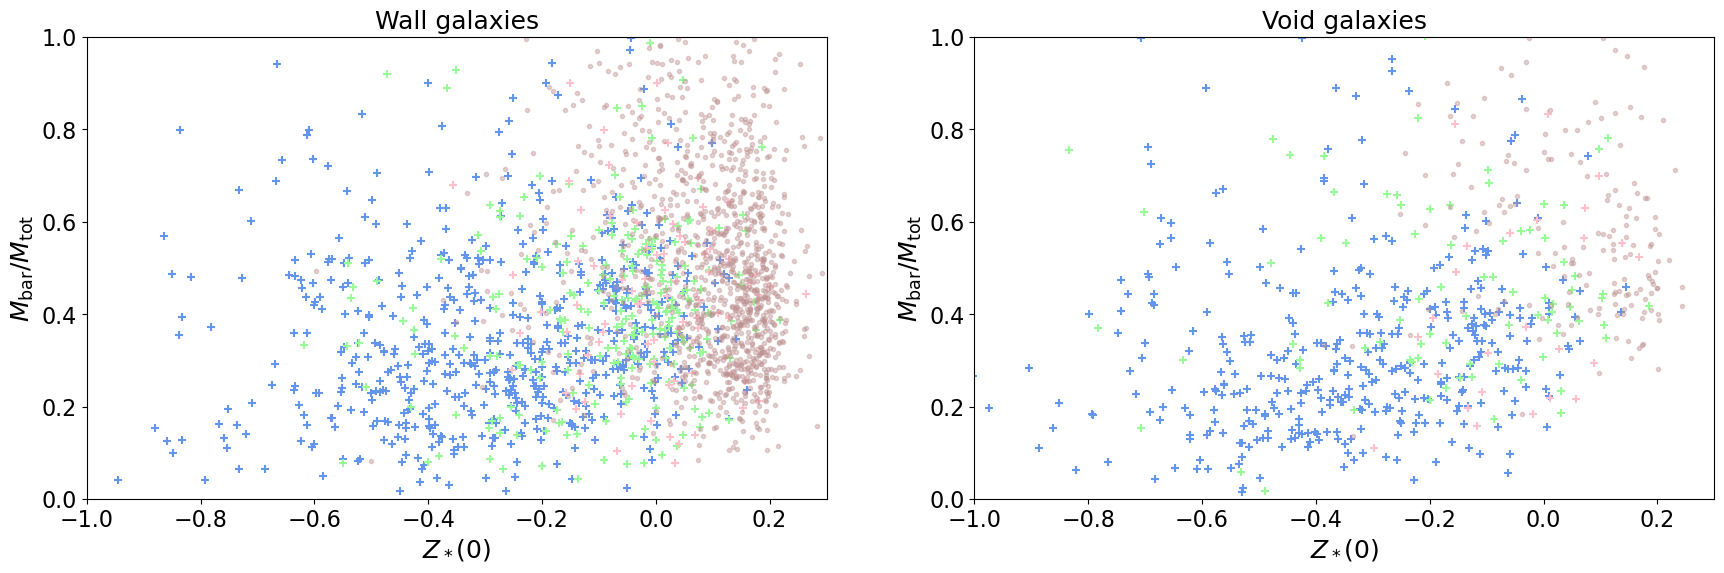

In [426]:
fig, ax = plt.subplots(1,2, figsize=(21,6))

ax[0].scatter(HI_b_spirals[HI_b_spirals['vflag_VF'] == 0]['stellar_Z_0'], HI_b_spirals[HI_b_spirals['vflag_VF'] == 0]['mbar_mtot'], color='cornflowerblue', marker='+')
ax[0].scatter(HI_g_spirals[HI_g_spirals['vflag_VF'] == 0]['stellar_Z_0'], HI_g_spirals[HI_g_spirals['vflag_VF'] == 0]['mbar_mtot'], color='palegreen', marker='+')
ax[0].scatter(HI_r_spirals[HI_r_spirals['vflag_VF'] == 0]['stellar_Z_0'], HI_r_spirals[HI_r_spirals['vflag_VF'] == 0]['mbar_mtot'], color='pink', marker='+')
ax[0].scatter(ellipticals[ellipticals['vflag_VF'] == 0]['stellar_Z_0'], ellipticals[ellipticals['vflag_VF'] == 0]['mstar_mtot'], color='rosybrown', marker='.', alpha=0.4)



ax[1].scatter(HI_b_spirals[HI_b_spirals['vflag_VF'] == 1]['stellar_Z_0'], HI_b_spirals[HI_b_spirals['vflag_VF'] == 1]['mbar_mtot'], color='cornflowerblue', marker='+')
ax[1].scatter(HI_g_spirals[HI_g_spirals['vflag_VF'] == 1]['stellar_Z_0'], HI_g_spirals[HI_g_spirals['vflag_VF'] == 1]['mbar_mtot'], color='palegreen', marker='+')
ax[1].scatter(HI_r_spirals[HI_r_spirals['vflag_VF'] == 1]['stellar_Z_0'], HI_r_spirals[HI_r_spirals['vflag_VF'] == 1]['mbar_mtot'], color='pink', marker='+')
ax[1].scatter(ellipticals[ellipticals['vflag_VF'] == 1]['stellar_Z_0'], ellipticals[ellipticals['vflag_VF'] == 1]['mstar_mtot'], color='rosybrown', marker='.', alpha=0.4)

for i in range(2):
    ax[i].tick_params(labelsize=16, axis='both')
    ax[i].set_xlim(-1,0.3)
    ax[i].set_ylim(0,1)
    ax[i].set_xlabel(r'$Z_*(0)$', fontsize=18)
    ax[i].set_ylabel(r'$M_{\rm bar}/M_{\rm tot}$', fontsize=18)

ax[0].set_title('Wall galaxies', fontsize=18)

ax[1].set_title('Void galaxies', fontsize=18)

fig.savefig(plot_dir + '/void_wall/stelz_mbarmtot_voidwall.png', bbox_inches='tight')

## separate void and wall grid plots

In [427]:
void_spirals = good_spirals[good_spirals['vflag_VF'] == 1]
void_ellipticals = ellipticals[ellipticals['vflag_VF'] ==1]

void_HI_spirals = HI_spirals[HI_spirals['vflag_VF']==1]
wall_HI_spirals = HI_spirals[HI_spirals['vflag_VF'] ==0]

wall_spirals = good_spirals[good_spirals['vflag_VF'] == 0]
wall_ellipticals = ellipticals[ellipticals['vflag_VF'] == 0]

In [428]:
wall_mrs = vstack([wall_HI_spirals['rabsmag'], wall_ellipticals['rabsmag']])['rabsmag']
wall_zs = vstack([wall_HI_spirals['stellar_Z_0'], wall_ellipticals['stellar_Z_0']])['stellar_Z_0']
wall_mbarmtot = vstack([wall_HI_spirals['mbar_mtot'], wall_ellipticals['mbar_mtot']])['mbar_mtot']


void_mrs = vstack([void_HI_spirals['rabsmag'], void_ellipticals['rabsmag']])['rabsmag']
void_zs = vstack([void_HI_spirals['stellar_Z_0'], void_ellipticals['stellar_Z_0']])['stellar_Z_0']
void_mbarmtot = vstack([void_HI_spirals['mbar_mtot'], void_ellipticals['mbar_mtot']])['mbar_mtot']

In [429]:
HI_mr_bins = np.linspace(-17, -23, 6)
HI_z_bins = np.linspace(-1, 0.3, 6)
wall_mr_indices = np.digitize(wall_mrs, HI_mr_bins, right=True)
wall_z_indices = np.digitize(wall_zs, HI_z_bins, right=True)

void_mr_indices = np.digitize(void_mrs, HI_mr_bins, right=True)
void_z_indices = np.digitize(void_zs, HI_z_bins, right=True)


wall_mbar_mtot_medians = np.zeros((5,5))
void_mbar_mtot_medians = np.zeros((5,5))

for i in range(1,6):
    for j in range(1,6):

        mask = np.logical_and(wall_mr_indices == i, wall_z_indices==j)
        data = wall_mbarmtot[mask]
        if len(data) < 10:
            med = np.nan
        else:
            med = ma.median(data)

        # med = ma.median(data)
        wall_mbar_mtot_medians[i-1][j-1] = med


        mask = np.logical_and(void_mr_indices == i, void_z_indices==j)
        data = void_mbarmtot[mask]
        if len(data) < 10:
            med = np.nan
        else:
            med = ma.median(data)

        # med = ma.median(data)
        void_mbar_mtot_medians[i-1][j-1] = med

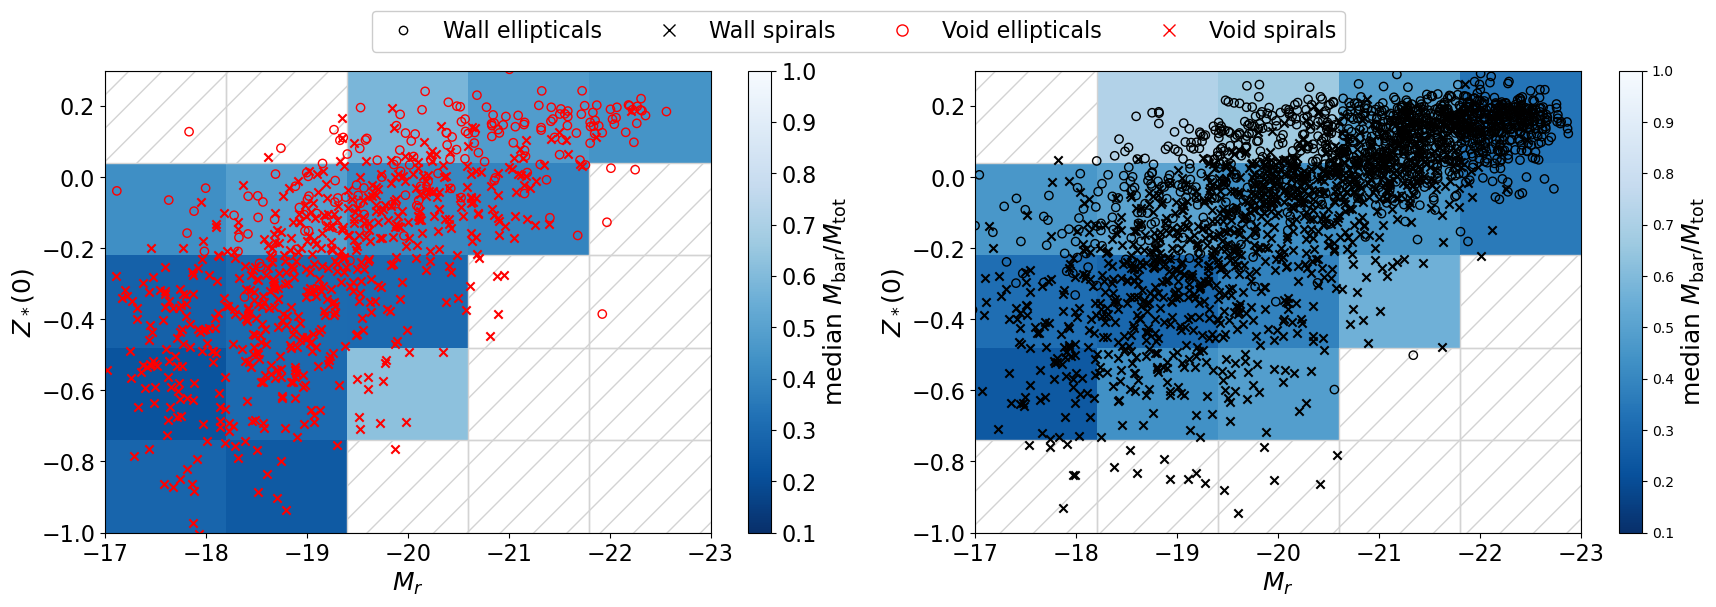

In [430]:
fig, ax = plt.subplots(1,2, figsize=(21,6))

im =ax[0].pcolormesh(HI_mr_bins, HI_z_bins, np.transpose(void_mbar_mtot_medians), vmin=0.1, vmax=1, cmap='Blues_r')
for i in range(5):
    for j in range(5):

        if np.isnan(void_mbar_mtot_medians[i][j]):
            # print('fill')
            ax[0].fill([HI_mr_bins[i], HI_mr_bins[i+1], HI_mr_bins[i+1], HI_mr_bins[i]], 
                     [HI_z_bins[j], HI_z_bins[j], HI_z_bins[j+1], HI_z_bins[j+1]], 'none', hatch='/', edgecolor='lightgrey')
cb = plt.colorbar(im, ax=ax[0])
cb.set_label(label=r'median $M_{\rm bar}/M_{\rm tot}$', size=18)
im.figure.axes[2].tick_params(axis="y", labelsize=16)


ax[0].scatter(void_HI_spirals['rabsmag'], void_HI_spirals['stellar_Z_0'], marker='x', color='r')
ax[0].scatter(void_ellipticals['rabsmag'], void_ellipticals['stellar_Z_0'], marker='o', color='r', facecolor='none')




im =ax[1].pcolormesh(HI_mr_bins, HI_z_bins, np.transpose(wall_mbar_mtot_medians), vmin=0.1, vmax=1, cmap='Blues_r')
for i in range(5):
    for j in range(5):

        if np.isnan(wall_mbar_mtot_medians[i][j]):
            # print('fill')
            ax[1].fill([HI_mr_bins[i], HI_mr_bins[i+1], HI_mr_bins[i+1], HI_mr_bins[i]], 
                     [HI_z_bins[j], HI_z_bins[j], HI_z_bins[j+1], HI_z_bins[j+1]], 'none', hatch='/', edgecolor='lightgrey')
cb = plt.colorbar(im, ax=ax[1])
cb.set_label(label=r'median $M_{\rm bar}/M_{\rm tot}$', size=18)
im.figure.axes[2].tick_params(axis="y", labelsize=16)

ax[1].scatter(wall_HI_spirals['rabsmag'], wall_HI_spirals['stellar_Z_0'], marker='x', color='k')
ax[1].scatter(wall_ellipticals['rabsmag'], wall_ellipticals['stellar_Z_0'], marker='o', color='k', facecolor='none')


# ax[0].scatter(good_spirals[good_spirals['vflag_VF']==0]['rabsmag'], good_spirals[good_spirals['vflag_VF']==0]['stellar_Z_0'],
#               marker='x', color='k')
# ax[0].scatter(good_spirals[good_spirals['vflag_VF']==1]['rabsmag'], good_spirals[good_spirals['vflag_VF']==1]['stellar_Z_0'],
#               marker='x', color='r')
# ax[0].scatter(ellipticals[ellipticals['vflag_VF']==0]['rabsmag'], ellipticals[ellipticals['vflag_VF']==0]['stellar_Z_0'],
#               marker='o', color='k', facecolor='none')
# ax[0].scatter(ellipticals[ellipticals['vflag_VF']==1]['rabsmag'], ellipticals[ellipticals['vflag_VF']==1]['stellar_Z_0'],
#               marker='o', color='r', facecolor='none')

ax[0].tick_params(labelsize=16, axis='both')
ax[0].set_xlim(-17,-23)
ax[0].set_ylim(-1,0.3)



ax[0].set_xlabel(r'$M_r$', fontsize=18)
ax[0].set_ylabel(r'$Z_*(0)$', fontsize=18)


# im =ax[1].pcolormesh(HI_mr_bins, HI_z_bins, np.transpose(mbar_mtot_medians), vmin=0.1, vmax=1, cmap='Blues_r')
# for i in range(5):
#     for j in range(5):

#         if np.isnan(mbar_mtot_medians[i][j]):
#             # print('fill')
#             ax[1].fill([HI_mr_bins[i], HI_mr_bins[i+1], HI_mr_bins[i+1], HI_mr_bins[i]], 
#                      [HI_z_bins[j], HI_z_bins[j], HI_z_bins[j+1], HI_z_bins[j+1]], 'none', hatch='/', edgecolor='lightgrey')
# cb = plt.colorbar(im, ax=ax[1])
# cb.set_label(label=r'median $M_{\rm bar}/M_{\rm tot}$', size=18)
# im.figure.axes[3].tick_params(axis="y", labelsize=16)
# ax[1].scatter(HI_b_spirals['rabsmag'], HI_b_spirals['stellar_Z_0'], color='cornflowerblue', marker='+')
# ax[1].scatter(HI_g_spirals['rabsmag'], HI_g_spirals['stellar_Z_0'], color='palegreen', marker='+')
# ax[1].scatter(HI_r_spirals['rabsmag'], HI_r_spirals['stellar_Z_0'], color='pink', marker='+')
# ax[1].scatter(ellipticals['rabsmag'], ellipticals['stellar_Z_0'], color='rosybrown', marker='.', alpha=0.4)

# ax[1].scatter(HI_spirals[HI_spirals['vflag_VF']==0]['rabsmag'], HI_spirals[HI_spirals['vflag_VF']==0]['stellar_Z_0'],
#               marker='x', color='k')
# ax[1].scatter(HI_spirals[HI_spirals['vflag_VF']==1]['rabsmag'], HI_spirals[HI_spirals['vflag_VF']==1]['stellar_Z_0'],
#               marker='x', color='r')
# ax[1].scatter(ellipticals[ellipticals['vflag_VF']==0]['rabsmag'], ellipticals[ellipticals['vflag_VF']==0]['stellar_Z_0'],
#               marker='o', color='k', facecolor='none')
# ax[1].scatter(ellipticals[ellipticals['vflag_VF']==1]['rabsmag'], ellipticals[ellipticals['vflag_VF']==1]['stellar_Z_0'],
#               marker='o', color='r', facecolor='none')

ax[1].tick_params(labelsize=16, axis='both')
plt.xlim(-17,-23)
plt.ylim(-1,0.3)

ax[1].set_xlabel(r'$M_r$', fontsize=18)
ax[1].set_ylabel(r'$Z_*(0)$', fontsize=18)

legend_elements = [Line2D([0], [0], marker='o', color='w', label='Wall ellipticals',
                          markeredgecolor='k', markerfacecolor='none', markersize=6),
                   Line2D([0], [0], marker='x', color='w', label='Wall spirals',
                          markeredgecolor='k', markerfacecolor='k', markersize=8),
                   Line2D([0], [0], marker='o', color='w', label='Void ellipticals',
                          markeredgecolor='r', markerfacecolor='none', markersize=8),
                   Line2D([0], [0], marker='x', color='w', label='Void spirals',
                          markeredgecolor='r', markerfacecolor='r', markersize=8),]

fig.legend(handles=legend_elements, loc='upper center', framealpha=1, ncols=4, fontsize=16)
fig.subplots_adjust(wspace=0.15,)
# fig.legend(handles=legend_elements, fontsize=14)

# plt.savefig(plot_dir + 'Mr_Zstel_MbarMtot_grid.png', bbox_inches='tight')

# plt.savefig(plot_dir + 'Mr_Zstel_MstarMtot_grid.png', bbox_inches='tight')

# plt.savefig(plot_dir + 'Mr_Zstel_ratio_grids.png', bbox_inches='tight')

# plt.savefig(plot_dir + '/void_wall/grids.png', bbox_inches='tight')

### take the difference in the medians between void and wall and plot that

In [431]:
np.max(np.abs(np.transpose(void_mbar_mtot_medians) - np.transpose(wall_mbar_mtot_medians)))

nan

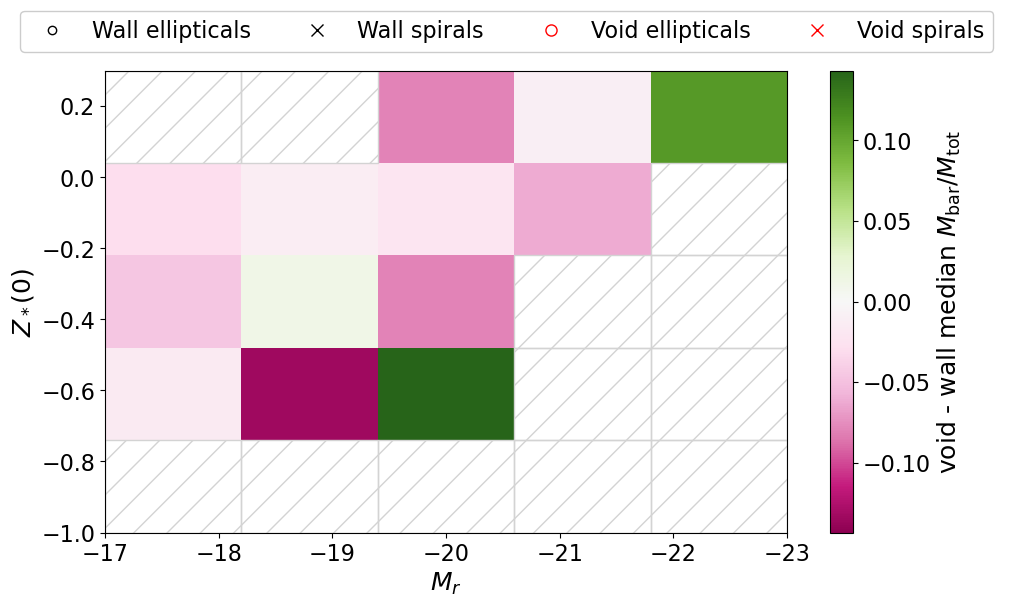

In [432]:
fig, ax = plt.subplots(figsize=(11,6))

vmax = np.nanmax(np.abs(np.transpose(void_mbar_mtot_medians) - np.transpose(wall_mbar_mtot_medians)))
vmin = -vmax

im =ax.pcolormesh(HI_mr_bins, HI_z_bins, np.transpose(void_mbar_mtot_medians) - np.transpose(wall_mbar_mtot_medians),  vmin=vmin, vmax=vmax,
                  cmap='PiYG')
for i in range(5):
    for j in range(5):

        if np.isnan(void_mbar_mtot_medians[i][j]) or np.isnan(wall_mbar_mtot_medians[i][j]):
            # print('fill')
            ax.fill([HI_mr_bins[i], HI_mr_bins[i+1], HI_mr_bins[i+1], HI_mr_bins[i]], 
                     [HI_z_bins[j], HI_z_bins[j], HI_z_bins[j+1], HI_z_bins[j+1]], 'none', hatch='/', edgecolor='lightgrey')
cb = plt.colorbar(im)
cb.set_label(label=r'void - wall median $M_{\rm bar}/M_{\rm tot}$', size=18)
im.figure.axes[1].tick_params(axis="y", labelsize=16)


# ax.scatter(void_HI_spirals['rabsmag'], void_HI_spirals['stellar_Z_0'], marker='x', color='r')
# ax.scatter(void_ellipticals['rabsmag'], void_ellipticals['stellar_Z_0'], marker='o', color='r', facecolor='none')


# ax.scatter(wall_HI_spirals['rabsmag'], wall_HI_spirals['stellar_Z_0'], marker='x', color='k')
# ax.scatter(wall_ellipticals['rabsmag'], wall_ellipticals['stellar_Z_0'], marker='o', color='k', facecolor='none')



ax.tick_params(labelsize=16, axis='both')
ax.set_xlim(-17,-23)
ax.set_ylim(-1,0.3)



ax.set_xlabel(r'$M_r$', fontsize=18)
ax.set_ylabel(r'$Z_*(0)$', fontsize=18)



legend_elements = [Line2D([0], [0], marker='o', color='w', label='Wall ellipticals',
                          markeredgecolor='k', markerfacecolor='none', markersize=6),
                   Line2D([0], [0], marker='x', color='w', label='Wall spirals',
                          markeredgecolor='k', markerfacecolor='k', markersize=8),
                   Line2D([0], [0], marker='o', color='w', label='Void ellipticals',
                          markeredgecolor='r', markerfacecolor='none', markersize=8),
                   Line2D([0], [0], marker='x', color='w', label='Void spirals',
                          markeredgecolor='r', markerfacecolor='r', markersize=8),]

fig.legend(handles=legend_elements, loc='upper center', framealpha=1, ncols=4, fontsize=16)
fig.subplots_adjust(wspace=0.15,)
# fig.legend(handles=legend_elements, fontsize=14)

# plt.savefig(plot_dir + 'Mr_Zstel_MbarMtot_grid.png', bbox_inches='tight')

# plt.savefig(plot_dir + 'Mr_Zstel_MstarMtot_grid.png', bbox_inches='tight')

# plt.savefig(plot_dir + 'Mr_Zstel_ratio_grids.png', bbox_inches='tight')

# plt.savefig(plot_dir + '/void_wall/grids.png', bbox_inches='tight')

### bin in mr and make histograms

In [465]:
for i in range(1,6):

    mask = HI_mr_indices == i
    all_data = mbar_mtot['mbar_mtot'][mask]
    
    mask = wall_mr_indices == i
    wall_data = wall_mbarmtot[mask]
    
    mask = void_mr_indices == i
    void_data = void_mbarmtot[mask]
    
    num_bins = int(np.sqrt(np.min([len(wall_data), len(void_data)]))) -1
    
    # min_val = np.min([np.min(wall_data), np.min(void_data)])
    # max_val = np.max([np.max(wall_data), np.max(void_data)])
    
    bins=np.linspace(0, 1, num_bins)

    plt.hist(all_data, bins=bins, color='lightgrey', density=True)
    plt.hist(wall_data, bins=bins, color='k', linestyle=':', histtype='step', linewidth=2, density=True)
    plt.hist(void_data, bins=bins, color='r', linestyle='-', histtype='step', linewidth=2, density=True)
    
    plt.title(fr'{HI_mr_bins[i-1]} > $M_r$ > {HI_mr_bins[i]}', fontsize=18)
    plt.xlabel(r'$M_{\rm bar}/M_{\rm tot}$', fontsize=18)
    plt.tick_params(axis='both', labelsize=16)
    
    plt.savefig(plot_dir + 'void_wall/mr_binned/' + str(i) + '_' + str(i+1) + '.png', bbox_inches='tight')

    plt.cla()
    plt.clf()
    plt.close()

### bin in z and make histograms

In [466]:
for i in range(1,6):

    mask = HI_z_indices == i
    all_data = mbar_mtot['mbar_mtot'][mask]
    
    mask = wall_z_indices == i
    wall_data = wall_mbarmtot[mask]
    
    mask = void_z_indices == i
    void_data = void_mbarmtot[mask]
    
    num_bins = int(np.sqrt(np.min([len(wall_data), len(void_data)]))) -1 
    
    # min_val = np.min([np.min(wall_data), np.min(void_data)])
    # max_val = np.max([np.max(wall_data), np.max(void_data)])
    
    bins=np.linspace(0, 1, num_bins)

    plt.hist(all_data, bins=bins, color='lightgrey', density=True)
    plt.hist(wall_data, bins=bins, color='k', linestyle=':', histtype='step', linewidth=2, density=True)
    plt.hist(void_data, bins=bins, color='r', linestyle='-', histtype='step', linewidth=2, density=True)
    
    plt.title(fr'{HI_z_bins[i-1]:.2f} < $Z_*(0)$ < {HI_z_bins[i]:.2f}', fontsize=18)
    plt.xlabel(r'$M_{\rm bar}/M_{\rm tot}$', fontsize=18)
    plt.tick_params(axis='both', labelsize=16)
    
    plt.savefig(plot_dir + 'void_wall/z_binned/' + str(i) + '_' + str(i+1) + '.png', bbox_inches='tight')

    plt.cla()
    plt.clf()
    plt.close()

## log bayes factor fun

In [471]:
from scipy.special import gammaln

def get_bayes_factor(data_1, data_2, c = 5, max_depth=6, aj=lambda depth: depth**2, log_BF=False):
    """
    nonparamteric Bayes factors

    parameters:

    data_1 : arraylike
        Numpy array of data points sampled from the first distribution
    data_2 : arraylike
        Numpy array of data points sampled from the second distribution
    c : int 
        The tunable paramter c descibed in https://arxiv.org/abs/0910.5060v3
    max_depth : int
        The maximum depth of the partially specified Polya tree as described in https://arxiv.org/abs/0910.5060v3
        The Polya tree has a tree height of max_depth.
    aj : function
        The prescription for calculateing aj terms as a function of tree depth 
        as described in https://arxiv.org/abs/0910.5060v3
    log_BF: bool
        When False, the Bayes factor is returned, and when True, log10(Bayes factor) is returned
    """

    data_switch = len(data_1)
    combined_data = np.concatenate([data_1, data_2])
    del data_1, data_2

    # partition the data into quartiles
    quantiles = np.quantile(combined_data, np.linspace(0,1,2**max_depth + 1))

    # get the log bayes factor
    logbf = _get_bayes_factor(combined_data, data_switch, quantiles, low=0, high=1, c=c, depth=1, max_depth=max_depth, aj=aj)

    # return either the bayes factor or log bayes factor
    if log_BF:
        log10bf = logbf / 2.302585092994046 # np.log(10) = 2.302585092994046
        return log10bf
    else:
        bf = np.exp(logbf)
        return bf

def _get_bayes_factor(combined_data, data_switch, quantiles, low, high, c, depth, max_depth,aj):
    """
    helper function called by get_bayes_factor

    parameters:

    combined_data : arraylike
        Numpy array of data points sampled from the first and second distributions. 
        Data from the second distribution hould follow after data from the first
    data_switch : int
        The array index seperating the two sampled distributions in combined_data
    low : float
        The low quantile for the current Polya tree node
    high : float
        The high quantile for the current Polya tree node
    c : int 
        The tunable paramter c descibed in https://arxiv.org/abs/0910.5060v3
    depth : int
        The depth of the current node in the Polya tree
    max_depth : int
        The maximum depth of the partially specified Polya tree as described in https://arxiv.org/abs/0910.5060v3
    aj : function
        The prescription for calculateing aj terms as a function of tree depth 
        as described in https://arxiv.org/abs/0910.5060v3
    
    """
    
    if depth > max_depth: 
        return 0

    # seelct quartiles
    low_q = quantiles[int((2**max_depth ) * low)]
    mid_q = quantiles[int((2**max_depth ) * (low+high)/2)]
    high_q = quantiles[int((2**max_depth ) * high)]

    # count data in quartiles
    if high == 1:
        data_1_low = np.count_nonzero((combined_data[:data_switch]>=low_q)*(combined_data[:data_switch]<=mid_q))
        data_2_low = np.count_nonzero((combined_data[data_switch:]>=low_q)*(combined_data[data_switch:]<=mid_q))
        data_1_high = np.count_nonzero((combined_data[:data_switch]>=mid_q)*(combined_data[:data_switch]<=high_q))
        data_2_high = np.count_nonzero((combined_data[data_switch:]>=mid_q)*(combined_data[data_switch:]<=high_q))
    else:
        data_1_low = np.count_nonzero((combined_data[:data_switch]>=low_q)*(combined_data[:data_switch]<mid_q))
        data_2_low = np.count_nonzero((combined_data[data_switch:]>=low_q)*(combined_data[data_switch:]<mid_q))
        data_1_high = np.count_nonzero((combined_data[:data_switch]>=mid_q)*(combined_data[:data_switch]<high_q))
        data_2_high = np.count_nonzero((combined_data[data_switch:]>=mid_q)*(combined_data[data_switch:]<high_q))

    # calculate the n_j terms for the current binnings
    data_1_n_j = [data_1_low, data_1_high]
    data_2_n_j = [data_2_low, data_2_high]

    # truncate the tree where there is no data
    if np.sum(data_1_n_j) == 0 or np.sum(data_2_n_j) == 0:
        return 0

    # calculate the a_j term for the current tree depth
    a_j = c * aj(depth)

    # calculate b_j

    log_gamma_summand_1 = 2 * gammaln(a_j) - gammaln(2 * a_j)
    log_gamma_summand_2 = gammaln(a_j + data_1_n_j[0] + data_2_n_j[0]) + gammaln(a_j + data_1_n_j[1] + data_2_n_j[1]) 
    log_gamma_summand_3 = - gammaln(2*a_j + data_1_n_j[0] + data_2_n_j[0] + data_1_n_j[1] + data_2_n_j[1])
    log_gamma_summand_4 = gammaln(2*a_j + data_1_n_j[0] + data_1_n_j[1]) + gammaln(2*a_j + data_2_n_j[0] + data_2_n_j[1])
    log_gamma_summand_5 = - gammaln(a_j + data_1_n_j[0]) - gammaln(a_j + data_2_n_j[0]) - gammaln(a_j + data_1_n_j[1]) - gammaln(a_j + data_2_n_j[1])

    log_b_j = log_gamma_summand_1 + log_gamma_summand_2 + log_gamma_summand_3 + log_gamma_summand_4 + log_gamma_summand_5

    # calculate the product of b_j terms on the left partition of the tree
    log_left_tree_b_j = _get_bayes_factor(combined_data, data_switch, quantiles, low, (low+high)/2, c, depth+1, max_depth, aj)

    # calculate the product of b_j terms on the right partition of the tree
    log_right_tree_b_j = _get_bayes_factor(combined_data, data_switch, quantiles, (low+high)/2, high, c, depth+1, max_depth, aj)

    # calculate the product of the b_j terms
    summed_b_j = log_b_j + log_left_tree_b_j + log_right_tree_b_j

    return summed_b_j

In [490]:
# central z
print('central z', get_bayes_factor(np.array(void_zs[void_zs < 1]), np.array(wall_zs[wall_zs < 1]), log_BF=1))

# Mr
print('Mr', get_bayes_factor(np.array(void_mrs), np.array(wall_mrs), log_BF=1))

# mstar mtot
print('mstar/mtot', get_bayes_factor(np.array(mstar_mtot['mstar_mtot'][vflag_se['vflag_VF'] == 0]), 
                                    np.array(mstar_mtot['mstar_mtot'][vflag_se['vflag_VF'] == 1]), log_BF=1))

# mbar mtot
print('mbar/mtot', get_bayes_factor(np.array(void_mbarmtot), np.array(wall_mbarmtot), log_BF=1))

central z -58.83369999819618
Mr -61.76232031993979
mstar/mtot -8.719911089712996
mbar/mtot -8.786797032028582


In [503]:
# for each bin in z and mr get the log bf

logbfs = np.zeros((5,5))
for i in range(1,6):
    for j in range(1,6):

        mask = np.logical_and(void_mr_indices == i, void_z_indices == j)
        void_data = void_mbarmtot[mask]
        
        mask = np.logical_and(wall_mr_indices == i, wall_z_indices == j)
        wall_data = wall_mbarmtot[mask]

        if len(void_data) >= 10 and len(wall_data) >= 10:
    
            logbfs[i-1][j-1] = get_bayes_factor(np.array(void_data), np.array(wall_data), log_BF=1)

In [504]:
logbfs

array([[ 0.        , -0.06352881, -0.13414534, -0.08712957,  0.        ],
       [ 0.        , -1.29243754,  0.07821822,  0.04985406,  0.        ],
       [ 0.        , -0.30965749, -0.06574109, -0.17126292, -0.00419554],
       [ 0.        ,  0.        ,  0.        , -1.22049088, -0.95314034],
       [ 0.        ,  0.        ,  0.        ,  0.        , -3.33629741]])

In [507]:
# for mr histograms get the log bf

logbfs = np.zeros(5)
for i in range(1,6):

    # mask = HI_mr_indices == i
    # all_data = mbar_mtot['mbar_mtot'][mask]
    
    mask = wall_mr_indices == i
    wall_data = wall_mbarmtot[mask]
    
    mask = void_mr_indices == i
    void_data = void_mbarmtot[mask]
    
    logbfs[i-1] = get_bayes_factor(np.array(void_data), np.array(wall_data), log_BF=1)

In [508]:
logbfs

array([-0.44470089, -1.69396509, -0.5425552 , -0.34666427, -3.81444567])

In [511]:
# for z histograms get the log bf

logbfs = np.zeros(5)
for i in range(1,6):

    # mask = HI_mr_indices == i
    # all_data = mbar_mtot['mbar_mtot'][mask]
    
    mask = wall_z_indices == i
    wall_data = wall_mbarmtot[mask]
    
    mask = void_z_indices == i
    void_data = void_mbarmtot[mask]
    
    logbfs[i-1] = get_bayes_factor(np.array(void_data), np.array(wall_data), log_BF=1)

In [512]:
logbfs

array([-0.02216666, -1.10925262, -0.28644369, -1.30449949, -4.0832854 ])

## mbar mtot vs mr

(0.0, 1.0)

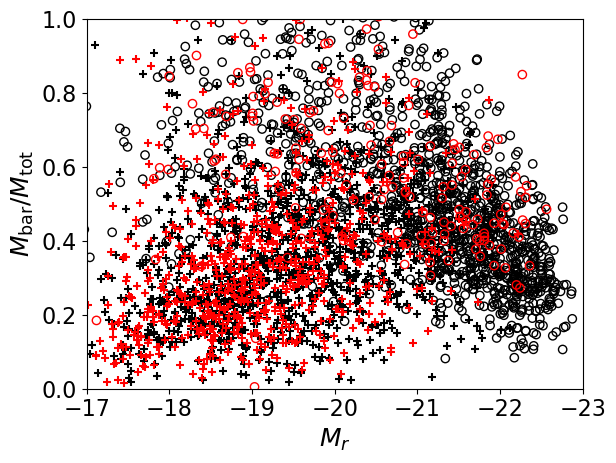

In [555]:
plt.scatter(wall_ellipticals['rabsmag'], wall_ellipticals['mbar_mtot'], marker='o', color='none', edgecolor='k')
plt.scatter(wall_HI_spirals['rabsmag'], wall_HI_spirals['mbar_mtot'], marker='+', color='k')


plt.scatter(void_ellipticals['rabsmag'], void_ellipticals['mbar_mtot'], marker='o', color='none', edgecolor='r')
plt.scatter(void_HI_spirals['rabsmag'], void_HI_spirals['mbar_mtot'], marker='+', color='r')


plt.xlabel(r'$M_r$', fontsize=18)
plt.ylabel(r'$M_{\rm bar}/M_{\rm tot}$', fontsize=18)

plt.tick_params(axis='both', labelsize=16)

plt.xlim(-17,-23)
plt.ylim(0,1)

In [564]:
wall_custom_bins[0]

array([0.        , 0.07142857, 0.14285714, 0.21428571, 0.28571429,
       0.35714286, 0.42857143, 0.5       , 0.57142857, 0.64285714,
       0.71428571, 0.78571429, 0.85714286, 0.92857143, 1.        ])

In [568]:
counts, bins=np.histogram(wall_data[0], wall_custom_bins[0])

In [569]:
counts

array([ 7, 29, 36, 28, 22, 16,  8, 12,  8,  9,  2,  7,  5,  1])

In [578]:
np.sqrt(len(void_HI_spirals))

26.90724809414742

In [595]:
wall_indices

array([4, 5, 5, ..., 4, 7, 6])

In [613]:
wall_bins = np.linspace(-17,-23,10)
wall_indices = np.digitize(wall_mrs, wall_bins)

wall_mr_mean = []
wall_data = []
wall_custom_bins = []

void_bins = np.concatenate([np.linspace(-17,-23,10)[:-2], [-23]])
void_indices = np.digitize(void_mrs, void_bins)

void_mr_mean = []
void_data = []
void_custom_bins = []

for i in range(1,len(wall_bins)):

    wall_data.append(wall_mbarmtot[wall_indices==i])
    wall_mr_mean.append(ma.mean(wall_mrs[wall_indices==i]))
    wall_custom_bins.append(np.linspace(0,1,int(np.sqrt(len(wall_data[i-1])))))

for i in range(1, len(void_bins)):
    
    void_data.append(void_mbarmtot[void_indices==i])
    void_mr_mean.append(ma.mean(void_mrs[void_indices==i]))
    void_custom_bins.append(np.linspace(0,1,int(np.sqrt(len(void_data[i-1])))))
    


wall_mr_mbarmtot_avg, wall_mr_mbarmtot_sig = fit_to_gaussian(wall_data, plot_dir = plot_dir + 'void_wall/mr_mbarmtot/', plot_name='mr_mbarmtot', xlab=r'$M_{\rm bar}/M_{\rm tot}$', plot_bins=wall_bins, bin_lab=r'$M_r$',
                                                            custom_bins=wall_custom_bins, use_custom_bins=1)

void_mr_mbarmtot_avg, void_mr_mbarmtot_sig = fit_to_gaussian(void_data, plot_dir = plot_dir + 'void_wall/mr_mbarmtot/', plot_name='void_mr_mbarmtot', xlab=r'$M_{\rm bar}/M_{\rm tot}$', plot_bins=void_bins, bin_lab=r'$M_r$',
                                                            custom_bins=void_custom_bins, use_custom_bins=1)


IndexError: list index out of range

(0.0, 1.0)

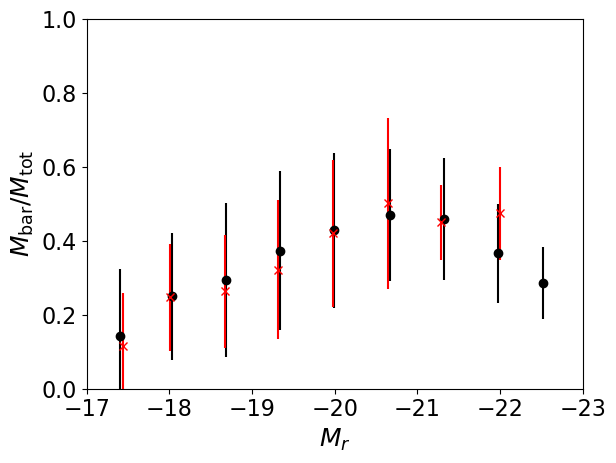

In [601]:
plt.errorbar(wall_mr_mean, wall_mr_mbarmtot_avg, yerr=wall_mr_mbarmtot_sig, linestyle='none', marker='o', color='k')
plt.errorbar(void_mr_mean, void_mr_mbarmtot_avg, yerr=void_mr_mbarmtot_sig, linestyle='none', marker='x', color='r')

plt.xlabel(r'$M_r$', fontsize=18)
plt.ylabel(r'$M_{\rm bar}/M_{\rm tot}$', fontsize=18)

plt.tick_params(axis='both', labelsize=16)

plt.xlim(-17,-23)
plt.ylim(0,1)

(0.0, 1.0)

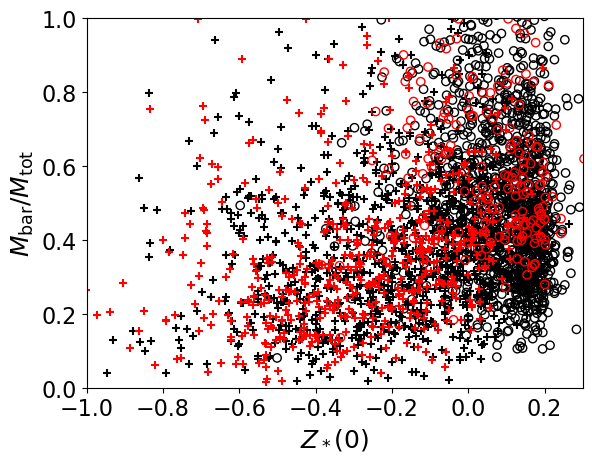

In [602]:
plt.scatter(wall_ellipticals['stellar_Z_0'], wall_ellipticals['mbar_mtot'], marker='o', color='none', edgecolor='k')
plt.scatter(wall_HI_spirals['stellar_Z_0'], wall_HI_spirals['mbar_mtot'], marker='+', color='k')


plt.scatter(void_ellipticals['stellar_Z_0'], void_ellipticals['mbar_mtot'], marker='o', color='none', edgecolor='r')
plt.scatter(void_HI_spirals['stellar_Z_0'], void_HI_spirals['mbar_mtot'], marker='+', color='r')


plt.xlabel(r'$Z_*(0)$', fontsize=18)
plt.ylabel(r'$M_{\rm bar}/M_{\rm tot}$', fontsize=18)

plt.tick_params(axis='both', labelsize=16)

plt.xlim(-1, 0.3)
plt.ylim(0,1)

In [608]:
np.linspace(-1,-0.3,10)[0]

-1.0

In [636]:
wall_bins = np.quantile(wall_zs[(wall_zs >= -1) & (wall_zs <= 0.3)], np.linspace(0,1, 10))
wall_indices = np.digitize(wall_zs, wall_bins)

wall_z_mean = []
wall_data = []
wall_custom_bins = []


void_bins =  np.quantile(void_zs[(void_zs >= -1) & (void_zs <= 0.3)], np.linspace(0,1, 10))
void_indices = np.digitize(void_zs, void_bins)
void_z_mean = []
void_data = []
void_custom_bins = []

for i in range(1,len(wall_bins)):

    wall_data.append(wall_mbarmtot[wall_indices==i])
    wall_z_mean.append(ma.mean(wall_zs[wall_indices==i]))
    wall_custom_bins.append(np.linspace(0,1,int(np.sqrt(len(wall_data[i-1])))))

for i in range(1,len(void_bins)):

    void_data.append(void_mbarmtot[void_indices==i])
    void_z_mean.append(ma.mean(void_zs[void_indices==i]))
    void_custom_bins.append(np.linspace(0,1,int(np.sqrt(len(void_data[i-1])))))
    


wall_z_mbarmtot_avg, wall_z_mbarmtot_sig = fit_to_gaussian(wall_data, plot_dir = plot_dir + 'void_wall/z_mbarmtot/', plot_name='z_mbarmtot', xlab=r'$M_{\rm bar}/M_{\rm tot}$', plot_bins=wall_bins, bin_lab=r'$M_r$',
                                                            custom_bins=wall_custom_bins, use_custom_bins=1)

void_z_mbarmtot_avg, void_z_mbarmtot_sig = fit_to_gaussian(void_data, plot_dir = plot_dir + 'void_wall/z_mbarmtot/', plot_name='void_z_mbarmtot', xlab=r'$M_{\rm bar}/M_{\rm tot}$', plot_bins=void_bins, bin_lab=r'$M_r$',
                                                            custom_bins=void_custom_bins, use_custom_bins=1)


0
1
2
3
4
5
6
7
8
0
1
2
3
4
5
6
7
8


(0.0, 1.0)

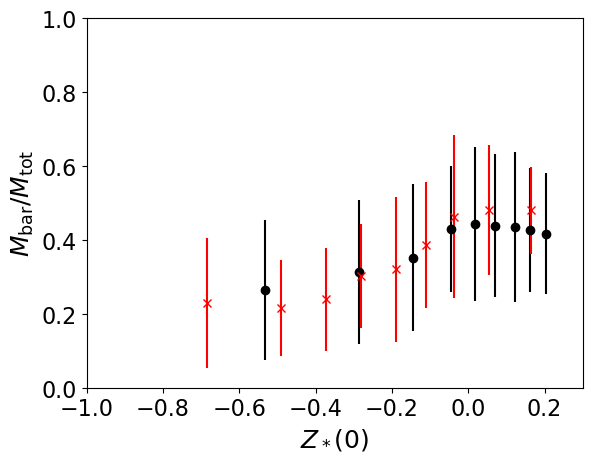

In [637]:
plt.errorbar(wall_z_mean, wall_z_mbarmtot_avg, yerr=wall_z_mbarmtot_sig, linestyle='none', marker='o', color='k')
plt.errorbar(void_z_mean, void_z_mbarmtot_avg, yerr=void_z_mbarmtot_sig, linestyle='none', marker='x', color='r')

plt.xlabel(r'$Z_*(0)$', fontsize=18)
plt.ylabel(r'$M_{\rm bar}/M_{\rm tot}$', fontsize=18)

plt.tick_params(axis='both', labelsize=16)

plt.xlim(-1,0.3)
plt.ylim(0,1)

## color metallicity diagram

In [514]:
wall_HI_spirals[:5]

plate,ifudsgn,plateifu,mangaid,versdrp2,versdrp3,verscore,versutil,versprim,platetyp,srvymode,objra,objdec,ifuglon,ifuglat,ifura,ifudec,ebvgal,nexp,exptime,drp3qual,bluesn2,redsn2,harname,frlplug,cartid,designid,cenra,cendec,airmsmin,airmsmed,airmsmax,seemin,seemed,seemax,transmin,transmed,transmax,mjdmin,mjdmed,mjdmax,gfwhm,rfwhm,ifwhm,zfwhm,mngtarg1,mngtarg2,mngtarg3,catidnum,plttarg,manga_tileid,nsa_iauname,ifudesignsize,ifutargetsize,ifudesignwrongsize,z,zmin,zmax,szmin,szmax,ezmin,ezmax,probs,pweight,psweight,psrweight,sweight,srweight,eweight,esweight,esrweight,nsa_field,nsa_run,nsa_camcol,nsa_version,nsa_nsaid,nsa_nsaid_v1b,nsa_z,nsa_zdist,nsa_sersic_absmag,nsa_elpetro_absmag,nsa_elpetro_amivar,nsa_sersic_mass,nsa_elpetro_mass,nsa_elpetro_ba,nsa_elpetro_phi,nsa_extinction,nsa_elpetro_th50_r,nsa_petro_th50,nsa_petro_flux,nsa_petro_flux_ivar,nsa_elpetro_flux,nsa_elpetro_flux_ivar,nsa_sersic_ba,nsa_sersic_n,nsa_sersic_phi,nsa_sersic_th50,nsa_sersic_flux,nsa_sersic_flux_ivar,smoothness_score,nsa_elpetro_th90,v_sys,v_sys_err,ba,ba_err,x0,x0_err,y0,y0_err,phi,phi_err,v_max,v_max_err,r_turn,r_turn_err,chi2,alpha,alpha_err,Rmax,M,M_err,fit_flag,Sigma_disk,Sigma_disk_err,R_disk,R_disk_err,rho_bulge,rho_bulge_err,R_bulge,R_bulge_err,M90_disk,M90_disk_err,M_disk,M_disk_err,chi2_disk,WF50,WF50_err,DL_ttype,vis_tidal,b,b_err,M_R90,M_R90_err,fit_function,A_g,A_r,logH2,R90_kpc,v_3p5,v_3p5_err,NSA_plate,NSA_fiberID,NSA_MJD,logH2_CG,logH2_CG_err,logH2_M,Z,Z_err,M_Z,M_Z_err,grad_Z,grad_Z_err,Z_0,Z_0_err,SFR,sSFR,SFR_err,sSFR_err,Flux_OII_3726,Flux_OII_3726_Err,Flux_OII_3728,Flux_OII_3728_Err,Flux_OIII_4958,Flux_OIII_4958_Err,Flux_OIII_5006,Flux_OIII_5006_Err,Flux_NII_6547,Flux_NII_6547_Err,Flux_NII_6583,Flux_NII_6583_Err,Flux_Ha_6562,Flux_Ha_6562_Err,Flux_Hb_4861,Flux_Hb_4861_Err,CMD_class,rabsmag_NSA,param_H2,param_H2_err,Z_map,Z_err_map,M_Z_map,M_Z_err_map,logHI_R90,Mvir,Mvir_err,star_sigma,star_sigma_err,dipole_moment,Rgal,vflag_VF,nsa_elpetro_log_mass,rabsmag,param_H2_R90,logHe,sphd_rho_c,sphd_rho_c_err,sphd_R_scale,sphd_R_scale_err,sphd_Sigma_d,sphd_Sigma_d_err,sphd_R_d,sphd_R_d_err,sphd_M_star,sphd_M_star_err,sphd_chi2,mhq_R_scale,mhq_R_scale_err,mhq_M_star,mhq_M_star_err,mhq_gamma,mhq_gamma_err,mhq_chi2,hq_R_scale,hq_R_scale_err,hq_M_star,hq_M_star_err,hq_chi2,sph_rho_c,sph_rho_c_err,sph_R_scale,sph_R_scale_err,sph_M_star,sph_M_star_err,sph_chi2,sum_M_star,sum_M_star_err,BPT_class,spiral_mask,elliptical_mask,Age_LW_Re_fit,Age_MW_Re_fit,ZH_LW_Re_fit,ZH_MW_Re_fit,M90_disk_h,M90_disk_err_h,sphd_M_star_err_h,sphd_M_star_h,V_R90,V_R90_err,e_M_star_R90,e_M_star_R90_err,e_M_star_R90_h,e_M_star_R90_err_h,v_eff,v_eff_err,logHI,logHI_err,HI_catalog,logHI_h,logHI_err_h,N2Ha,O3Hb,nsa_u_r,illustris_match,illustris_dist,illustris_u_r,illustris_Mstar,illustris_Mstar_Sal,illustris_Vmax,illustris_flag,illustris_MR90,MH2_S14_vol,MHI_S14_vol,MHtot,stellar_grad_Z,stellar_grad_Z_err,stellar_Z_0,stellar_Z_0_err,alpha_ZH_LW_Re_fit,p3d_R50_arc,R50_kpc,p3d_R50_kpc,p3d_stelz_slope,R50_Z,stellar_Z_Re,stellar_Z_Re_err,gas_Z_Re,gas_Z_Re_err,Mstar_MHI_h,Mstar_MHI_err_h,param_H2_h,param_He_h,param_He90_h,logHI_R90_h,mbar_mtot
int64,bytes32,bytes32,bytes32,bytes32,bytes32,bytes32,bytes32,bytes32,bytes32,bytes32,float64,float64,float64,float64,float64,float64,float64,int64,float64,int64,float64,float64,bytes53,int64,bytes32,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,int64,int64,int64,float64,float64,float64,float64,int64,int64,int64,int64,bytes32,int64,bytes19,int64,int64,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,int64,int64,int64,bytes6,int64,int64,float64,float64,float64[7],float64[7],float64[7],float64,float64,float64,float64,float64[7],float64,float64,float64[7],float64[7],float64[7],float64[7],float64,float64,float64,float64,float64[7],float64[7],float64,float64,float64,float64,float64,float64,float64,float64,float64,

(0.5, 3.0)

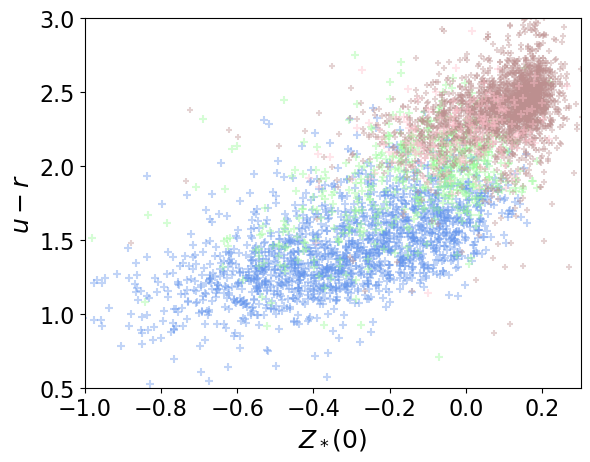

In [540]:
plt.scatter(blue_HI_spirals['stellar_Z_0'], blue_HI_spirals['nsa_u_r'], marker='+', alpha=0.4, color='cornflowerblue')
plt.scatter(green_HI_spirals['stellar_Z_0'], green_HI_spirals['nsa_u_r'], marker='+', alpha=0.4, color='palegreen')
# plt.scatter(red_HI_spirals['stellar_Z_0'], red_HI_spirals['nsa_u_r'], marker='+', alpha=0.4, color='pink')

plt.scatter(ellipticals['stellar_Z_0'], ellipticals['nsa_u_r'], marker='+', alpha=0.4, color='rosybrown', s=15)
plt.scatter(red_HI_spirals['stellar_Z_0'], red_HI_spirals['nsa_u_r'], marker='+', alpha=0.4, color='pink')


plt.ylabel(r'$u-r$', fontsize=18)
plt.xlabel(r'$Z_*(0)$', fontsize=18)

plt.tick_params(axis='both', labelsize=16)

plt.xlim(-1,0.3)
plt.ylim(0.5,3)

(0.5, 3.0)

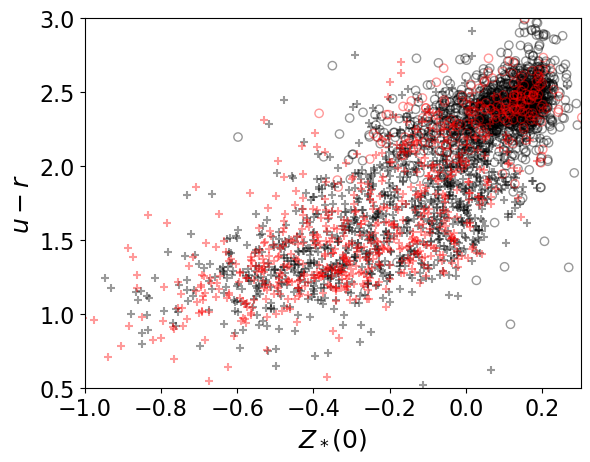

In [552]:
plt.scatter(wall_HI_spirals['stellar_Z_0'], wall_HI_spirals['nsa_u_r'], marker='+', alpha=0.4, color='k')
plt.scatter(wall_ellipticals['stellar_Z_0'], wall_ellipticals['nsa_u_r'], marker='o', alpha=0.4, color='none', edgecolor='k')

plt.scatter(void_HI_spirals['stellar_Z_0'], void_HI_spirals['nsa_u_r'], marker='+', alpha=0.4, color='r')
plt.scatter(void_ellipticals['stellar_Z_0'], void_ellipticals['nsa_u_r'], marker='o', alpha=0.4, color='none', edgecolor='r')

plt.ylabel(r'$u-r$', fontsize=18)
plt.xlabel(r'$Z_*(0)$', fontsize=18)

plt.tick_params(axis='both', labelsize=16)


plt.xlim(-1,0.3)
plt.ylim(0.5,3)

## cmd color by metallicity

Text(0, 0.5, '$u-r$')

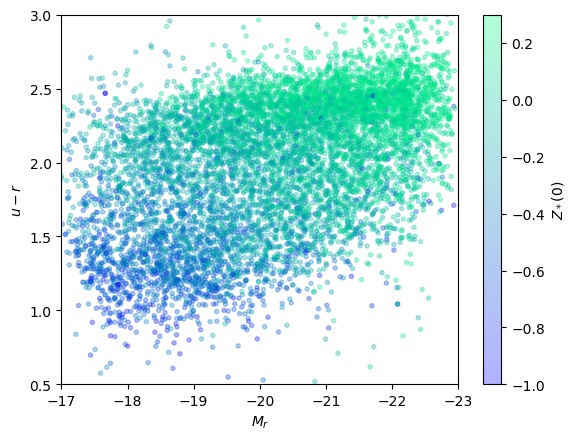

In [548]:
plt.scatter(good_stelz['rabsmag'], good_stelz['nsa_u_r'], c=good_stelz['stellar_Z_0'], marker='.', alpha=0.3, cmap='winter', vmin=-1, vmax=0.3)
plt.colorbar(label=r'$Z_*(0)$')

plt.xlim(-17,-23)
plt.ylim(0.5,3)

plt.xlabel(r'$M_r$')
plt.ylabel(r'$u-r$')